# **Assignment 2 - Customer and Marketing analytics:**
##Analysing Sentiment, Topics and Emojis in Brand Social Media Posts

# **Q0 — Data Loading and Preparation**

### Importing files and libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob

In [ ]:
# Load the CSV file into a pandas DataFrame
df = pd.read_csv('Team Assignment 2 Data 2026.csv', encoding='utf-8-sig')

# Display the first 5 rows of the DataFrame
display(df.head())

,Post_ID,Brand,Handle,Post_Text,Total_Followers,Total_Posts_LastYear,Num_Likes,Num_Comments,Num_Reposts
0,1,LumoraBeauty,@LumoraBeauty,The order matters! Skincare layering: cleanser...,485000,318,2347,69,325
1,2,LumoraBeauty,@LumoraBeauty,Current mood: applying a sheet mask and preten...,485000,318,3542,489,498
2,3,LumoraBeauty,@LumoraBeauty,Your skin deserves a standing ovation today 👏✨...,485000,318,2747,119,649
3,4,LumoraBeauty,@LumoraBeauty,"Our ClearCalm Blemish Serum has over 10,000 fi...",485000,318,3185,188,286
4,5,LumoraBeauty,@LumoraBeauty,Retinol 101 🧪 Start with 0.25% twice a week at...,485000,318,1202,229,366


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Post_ID               600 non-null    int64 
 1   Brand                 600 non-null    object
 2   Handle                600 non-null    object
 3   Post_Text             600 non-null    object
 4   Total_Followers       600 non-null    int64 
 5   Total_Posts_LastYear  600 non-null    int64 
 6   Num_Likes             600 non-null    int64 
 7   Num_Comments          600 non-null    int64 
 8   Num_Reposts           600 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 42.3+ KB


In [ ]:
# Missing values
df.isnull().sum()


,0
Post_ID,0
Brand,0
Handle,0
Post_Text,0
Total_Followers,0
Total_Posts_LastYear,0
Num_Likes,0
Num_Comments,0
Num_Reposts,0


In [ ]:
#Brand distribution
df['Brand'].value_counts()

,count
Brand,
LumoraBeauty,200
FitPulse,200
TechNest,200


> **Note:** The dataset is perfectly balanced across brands.

In [ ]:
#Sample post text for each brand
for brand, group in df.groupby('Brand'):
    print(f"\n[{brand}]\n{group['Post_Text'].iloc[0]}\n")


[FitPulse]
Your dream home gym starts here 🏠💪 The FitPulse Power Bundle, adjustable dumbbells plus bands plus mat, is on sale this week at 25% off 🎉 Shop now via link in bio!


[LumoraBeauty]
The order matters! Skincare layering: cleanser, toner, serum, eye cream, moisturiser, SPF (AM) or facial oil (PM) 🌸 Save this post for your next routine refresh 💛


[TechNest]
Stop losing bandwidth through that throttled old hub 🚫⚠️ The TechNest MX Hub delivers full USB3.2 speeds. Your peripherals deserve better. Link in bio ⚡



### Data preparation

In [ ]:
df.groupby('Brand')[['Total_Followers', 'Total_Posts_LastYear']].first()

,Total_Followers,Total_Posts_LastYear
Brand,,
FitPulse,312000,276
LumoraBeauty,485000,318
TechNest,218000,194



--- Visualizing engagement for Brand: LumoraBeauty ---


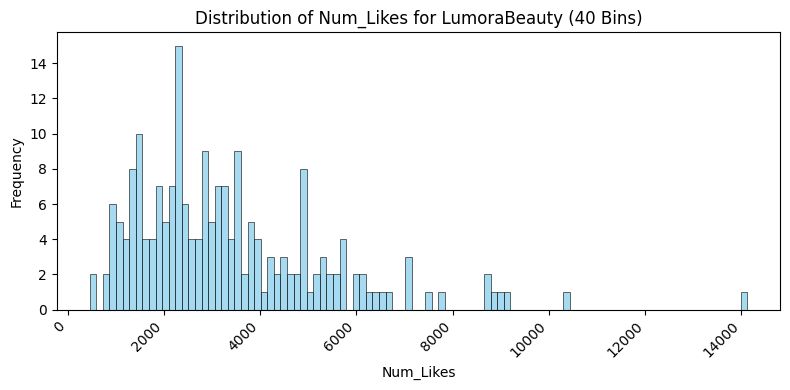

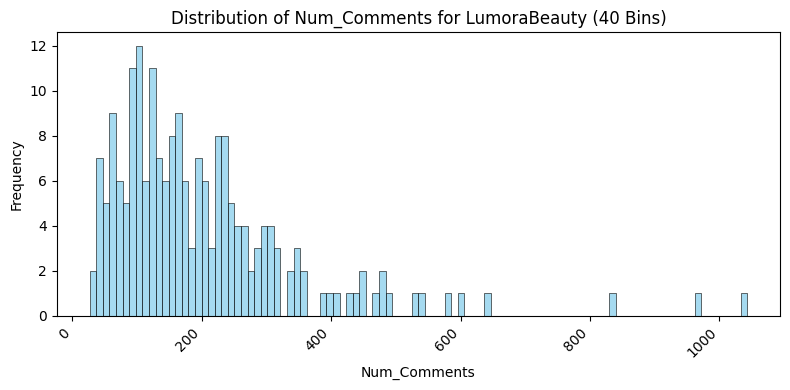

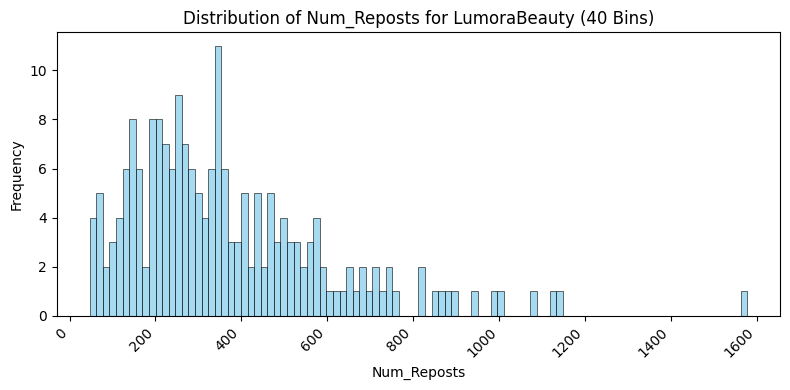


--- Visualizing engagement for Brand: FitPulse ---


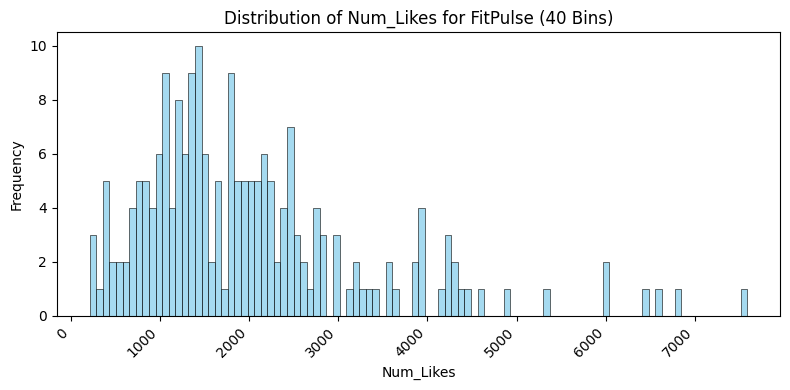

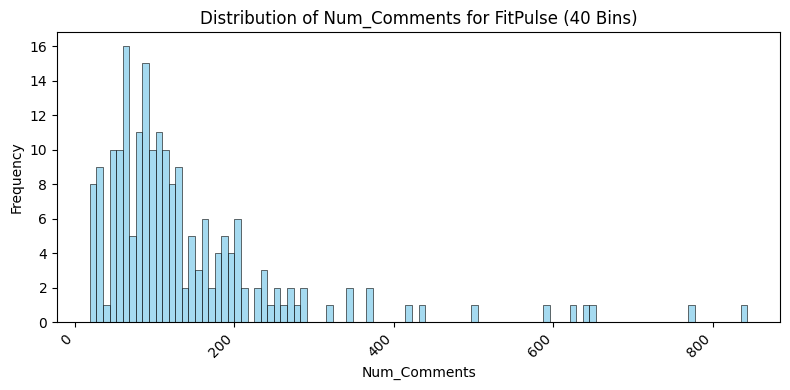

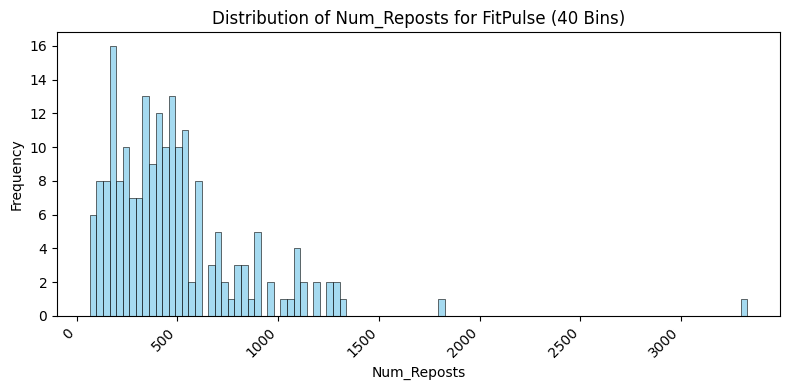


--- Visualizing engagement for Brand: TechNest ---


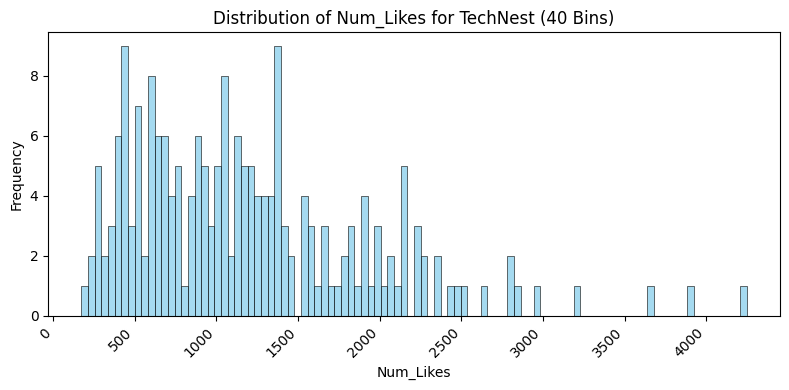

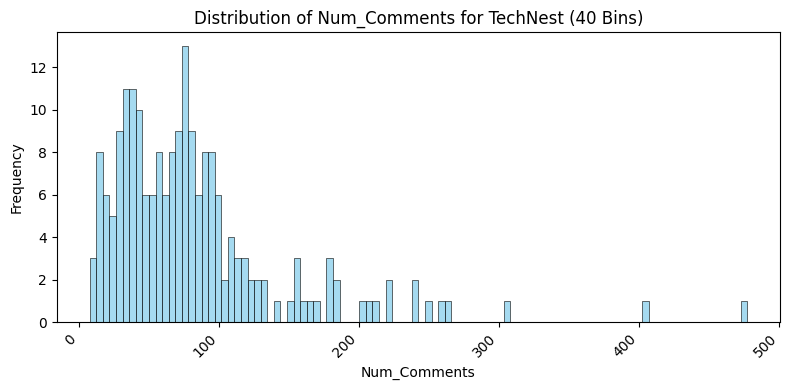

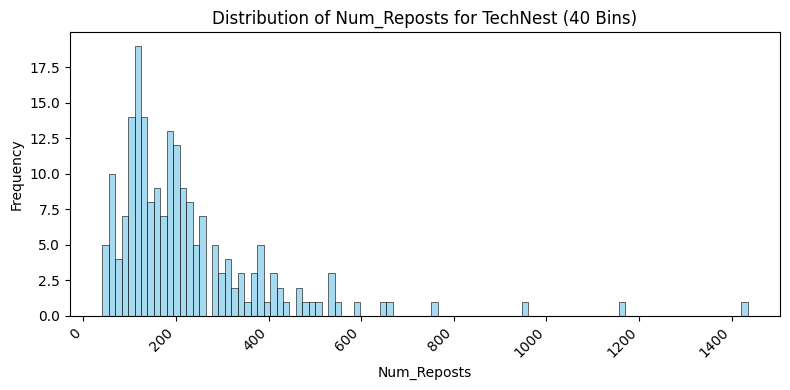

In [ ]:

engagement_columns = ['Num_Likes', 'Num_Comments', 'Num_Reposts']
unique_brands = df['Brand'].unique()

for brand in unique_brands:
    brand_df = df[df['Brand'] == brand]
    print(f"\n--- Visualizing engagement for Brand: {brand} ---")
    for col in engagement_columns:
        plt.figure(figsize=(8, 4))
        # Changed to histplot with 40 bins
        sns.histplot(data=brand_df, x=col, bins=100, kde=False, color='skyblue')
        plt.title(f'Distribution of {col} for {brand} (40 Bins)')
        plt.xlabel(col)
        plt.ylabel('Frequency')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

In [ ]:
# Additional checks

print("\nDuplicate checks:")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Post_IDs:", df["Post_ID"].duplicated().sum())

print("\nSample post texts with emojis:")
display(df[["Brand", "Handle", "Post_Text"]].head(10))


Duplicate checks:
Duplicate rows: 0
Duplicate Post_IDs: 0

Sample post texts with emojis:


,Brand,Handle,Post_Text
0,LumoraBeauty,@LumoraBeauty,The order matters! Skincare layering: cleanser...
1,LumoraBeauty,@LumoraBeauty,Current mood: applying a sheet mask and preten...
2,LumoraBeauty,@LumoraBeauty,Your skin deserves a standing ovation today 👏✨...
3,LumoraBeauty,@LumoraBeauty,"Our ClearCalm Blemish Serum has over 10,000 fi..."
4,LumoraBeauty,@LumoraBeauty,Retinol 101 🧪 Start with 0.25% twice a week at...
5,LumoraBeauty,@LumoraBeauty,AHA vs BHA: AHAs (like glycolic acid) resurfac...
6,LumoraBeauty,@LumoraBeauty,Skincare personality test 🧴 Are you a 3-step m...
7,LumoraBeauty,@LumoraBeauty,Glow-up season is every season with Lumora 🌸✨ ...
8,LumoraBeauty,@LumoraBeauty,LIMITED TIME ✨ Buy any 2 Lumora skincare produ...
9,LumoraBeauty,@LumoraBeauty,"If your skincare routine had a soundtrack, wha..."


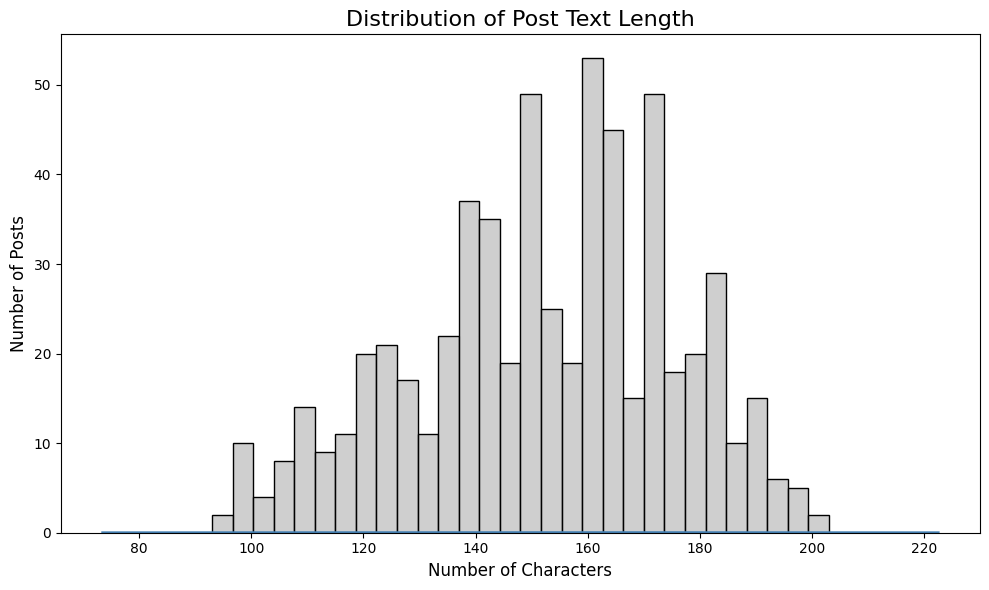

In [ ]:
df["Text_Length"] = df["Post_Text"].astype(str).str.len()

plt.figure(figsize=(10, 6))

# Histogram without KDE
sns.histplot(df["Text_Length"], bins=30, kde=False, color='#C0C0C0')

# KDE line separately with blue color
sns.kdeplot(df["Text_Length"], color='steelblue', linewidth=2)

plt.title("Distribution of Post Text Length", fontsize=16)
plt.xlabel("Number of Characters", fontsize=12)
plt.ylabel("Number of Posts", fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()

# **Q1 — Sentiment Analysis: How Positive Are the Posts?**

Uses a Hugging Face Transformers sentiment model to score each post, adds VADER as a lightweight robustness check, compares sentiment by brand, checks very high and low sentiment examples, and saves a new CSV for later questions.

### 1. Import Libraries

In [ ]:
import importlib
import subprocess
import sys

required_packages = {
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "transformers": "transformers",
    "torch": "torch",
    "vaderSentiment": "vaderSentiment",
}

for module_name, package_name in required_packages.items():
    try:
        importlib.import_module(module_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

### 2. Calculate Sentiment Scores

We use a Hugging Face Transformers model as the primary sentiment method: `cardiffnlp/twitter-roberta-base-sentiment-latest`. This model is designed for English social-media-style text and returns probabilities for negative, neutral, and positive sentiment.

For Q4, we convert the model probabilities into one numeric score:

`Sentiment_Score = Positive probability - Negative probability`

This keeps the score on an interpretable scale:

- `-1` means very negative
- `0` means neutral
- `+1` means very positive

We also calculate VADER compound sentiment as a lightweight robustness check.

In [ ]:
HF_MODEL = "cardiffnlp/twitter-roberta-base-sentiment-latest"

# First run downloads the model. This may take a few minutes, especially on CPU.
hf_sentiment = pipeline(
    "sentiment-analysis",
    model=HF_MODEL,
    tokenizer=HF_MODEL,
    top_k=None,
    truncation=True,
)

posts = df["Post_Text"].astype(str).tolist()
hf_results = hf_sentiment(posts, batch_size=16)

def normalize_hf_scores(result):
    label_map = {
        "label_0": "negative",
        "label_1": "neutral",
        "label_2": "positive",
        "negative": "negative",
        "neutral": "neutral",
        "positive": "positive",
    }
    scores = {"negative": 0.0, "neutral": 0.0, "positive": 0.0}

    if isinstance(result, dict):
        result = [result]

    for item in result:
        label = label_map[item["label"].lower()]
        scores[label] = item["score"]

    return scores


hf_scores = pd.DataFrame([normalize_hf_scores(result) for result in hf_results])

df["HF_Negative_Prob"] = hf_scores["negative"]
df["HF_Neutral_Prob"] = hf_scores["neutral"]
df["HF_Positive_Prob"] = hf_scores["positive"]
df["Sentiment_Score"] = df["HF_Positive_Prob"] - df["HF_Negative_Prob"]

probability_columns = ["HF_Negative_Prob", "HF_Neutral_Prob", "HF_Positive_Prob"]
label_names = {
    "HF_Negative_Prob": "Negative",
    "HF_Neutral_Prob": "Neutral",
    "HF_Positive_Prob": "Positive",
}
df["HF_Sentiment_Label"] = df[probability_columns].idxmax(axis=1).map(label_names)

vader_analyzer = SentimentIntensityAnalyzer()
df["VADER_Compound"] = df["Post_Text"].astype(str).apply(
    lambda text: vader_analyzer.polarity_scores(text)["compound"]
)

display(df[["Post_ID", "Brand", "HF_Sentiment_Label", "Sentiment_Score", "HF_Positive_Prob", "HF_Neutral_Prob", "HF_Negative_Prob", "VADER_Compound", "Post_Text"]].head(10))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,Post_ID,Brand,HF_Sentiment_Label,Sentiment_Score,HF_Positive_Prob,HF_Neutral_Prob,HF_Negative_Prob,VADER_Compound,Post_Text
0,1,LumoraBeauty,Positive,0.629168,0.636722,0.355723,0.007555,0.8313,"The order matters! Skincare layering: cleanser, toner, serum, eye cream, moisturiser, SPF (AM) or facial oil (PM) 🌸 Save this post for your next routine ref..."
1,2,LumoraBeauty,Positive,0.586299,0.607823,0.370654,0.021523,0.4199,Current mood: applying a sheet mask and pretending it is a luxury spa day 🧖🥂 Anyone else? Drop a 🙋 if self-care Sunday is sacred to you!
2,3,LumoraBeauty,Positive,0.970223,0.975670,0.018883,0.005447,0.9381,Your skin deserves a standing ovation today 👏✨ Drop a compliment for a fellow skincare lover below. Good vibes only in Lumora comments! 💛🌸
3,4,LumoraBeauty,Positive,0.956013,0.959248,0.037518,0.003234,0.7579,"Our ClearCalm Blemish Serum has over 10,000 five-star reviews 🙌⭐ Visible results in 72 hours or your money back. Try it risk-free. Link in bio 💚✨"
4,5,LumoraBeauty,Positive,0.865264,0.868750,0.127764,0.003486,0.7184,"Retinol 101 🧪 Start with 0.25% twice a week at night, always follow with SPF the next morning. Our Lumora Night Renewal Serum is perfect for beginners ✨🌙"
5,6,LumoraBeauty,Positive,0.801957,0.810463,0.181030,0.008507,0.8658,AHA vs BHA: AHAs (like glycolic acid) resurface the top layer for glow and texture 🌟 BHAs (like salicylic acid) go deeper into pores for blemish control 🧴 B...
6,7,LumoraBeauty,Neutral,0.141065,0.164517,0.812030,0.023453,0.6315,Skincare personality test 🧴 Are you a 3-step minimalist or a full 10-step devotee? No wrong answers 👇
7,8,LumoraBeauty,Positive,0.986542,0.988383,0.009777,0.001841,0.9538,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌
8,9,LumoraBeauty,Positive,0.923099,0.924726,0.073647,0.001627,0.9041,LIMITED TIME ✨ Buy any 2 Lumora skincare products and receive our Rose Glow face mask FREE 🌸🎁 Offer ends Sunday. Link in bio to grab yours! 💕
9,10,LumoraBeauty,Positive,0.866213,0.870853,0.124507,0.004640,0.7327,"If your skincare routine had a soundtrack, what would it be? 🎵✨ Ours would be slow, luxurious and a little glittery 💫💛 Let us know below!"


### 4. Overall Sentiment Distribution

,Sentiment_Score,HF_Positive_Prob,HF_Neutral_Prob,HF_Negative_Prob,VADER_Compound
count,600.000,600.000,600.000,600.000,600.000
mean,0.445,0.562,0.322,0.117,0.343
std,0.539,0.350,0.260,0.237,0.482
min,-0.932,0.007,0.009,0.001,-0.826
25%,0.141,0.201,0.094,0.004,0.000
50%,0.619,0.637,0.244,0.008,0.457
75%,0.878,0.884,0.522,0.066,0.758
max,0.987,0.988,0.936,0.939,0.959


,HF_Sentiment_Label,Number_of_Posts,Percent
0,Positive,350,58.3
1,Neutral,190,31.7
2,Negative,60,10.0


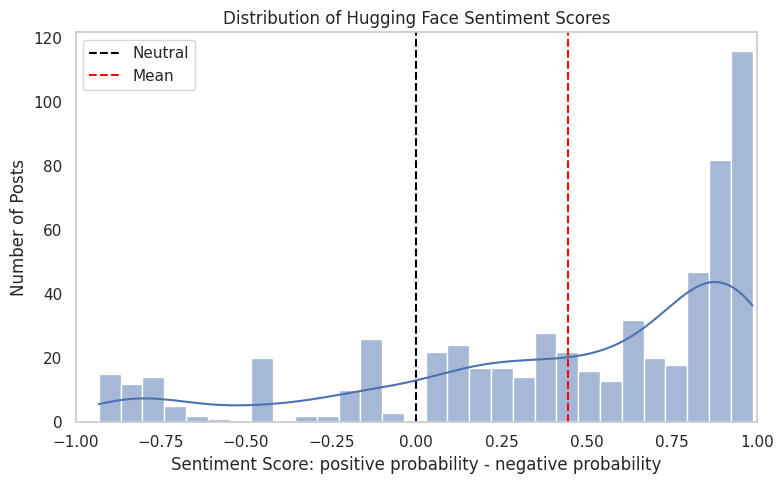

In [ ]:
sentiment_summary = df[["Sentiment_Score", "HF_Positive_Prob", "HF_Neutral_Prob", "HF_Negative_Prob", "VADER_Compound"]].describe().round(3)
display(sentiment_summary)

label_distribution = df["HF_Sentiment_Label"].value_counts().rename_axis("HF_Sentiment_Label").reset_index(name="Number_of_Posts")
label_distribution["Percent"] = (label_distribution["Number_of_Posts"] / len(df) * 100).round(1)
display(label_distribution)

plt.figure(figsize=(8, 5))
sns.histplot(df["Sentiment_Score"], bins=30, kde=True)
plt.axvline(0, color="black", linestyle="--", label="Neutral")
plt.axvline(df["Sentiment_Score"].mean(), color="red", linestyle="--", label="Mean")
plt.xlim(-1, 1)
plt.title("Distribution of Hugging Face Sentiment Scores")
plt.xlabel("Sentiment Score: positive probability - negative probability")
plt.ylabel("Number of Posts")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

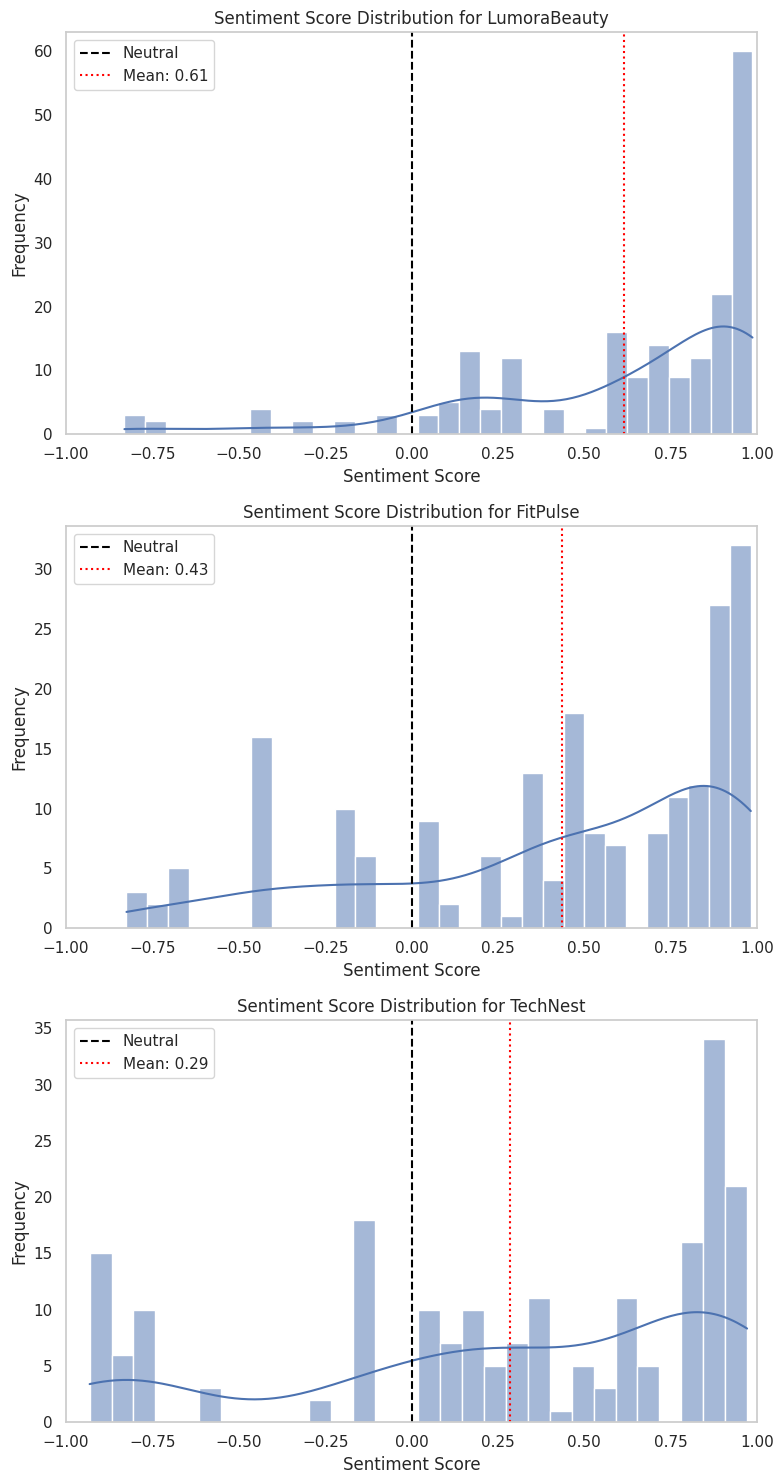

In [ ]:
unique_brands = df['Brand'].unique()

plt.figure(figsize=(8, 15)) # Adjusted figure size for 3 rows
for i, brand in enumerate(unique_brands):
    plt.subplot(len(unique_brands), 1, i + 1) # Changed to 3 rows, 1 column
    brand_sentiment_mean = df[df['Brand'] == brand]['Sentiment_Score'].mean()
    sns.histplot(df[df['Brand'] == brand]['Sentiment_Score'], bins=30, kde=True)
    plt.title(f'Sentiment Score Distribution for {brand}')
    plt.xlabel('Sentiment Score')
    plt.ylabel('Frequency')
    plt.xlim(-1, 1)
    plt.axvline(0, color='black', linestyle='--', label='Neutral')
    plt.axvline(brand_sentiment_mean, color='red', linestyle=':', label=f'Mean: {brand_sentiment_mean:.2f}')
    plt.legend()
    plt.grid(False) # Removed grid lines
plt.tight_layout()
plt.show()

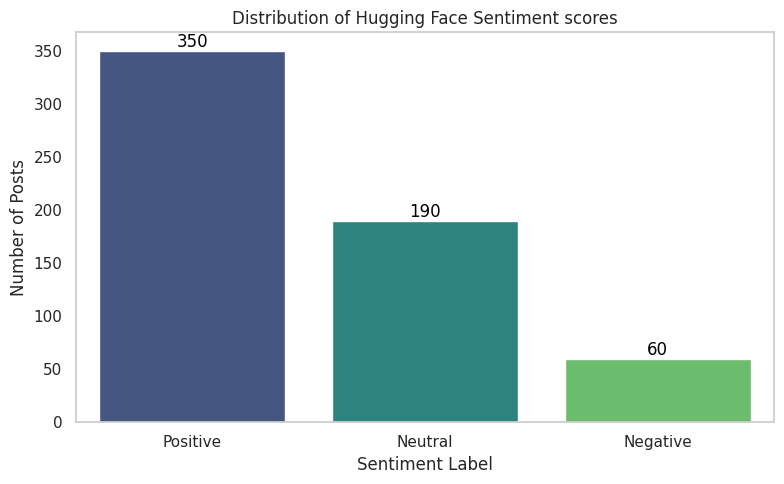

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x='HF_Sentiment_Label', y='Number_of_Posts', data=label_distribution, palette='viridis', hue='HF_Sentiment_Label', legend=False)
plt.title('Distribution of Hugging Face Sentiment scores')
plt.xlabel('Sentiment Label')
plt.ylabel('Number of Posts')

# Add labels to the bars
for index, row in label_distribution.iterrows():
    plt.text(index, row['Number_of_Posts'], f"{row['Number_of_Posts']}", color='black', ha="center", va="bottom")

ax.grid(False) # Remove grid lines
plt.tight_layout()
plt.show()

### 5. Sentiment by Brand

This tells us which brand is most positive on average. The table includes the Hugging Face score as the main measure and VADER as a comparison measure.

In [ ]:
brand_sentiment = df.groupby("Brand").agg(
    posts=("Post_ID", "count"),
    hf_mean=("Sentiment_Score", "mean"),
    hf_median=("Sentiment_Score", "median"),
    hf_std=("Sentiment_Score", "std"),
    positive_share=("HF_Sentiment_Label", lambda labels: (labels == "Positive").mean() * 100),
    vader_mean=("VADER_Compound", "mean"),
    vader_median=("VADER_Compound", "median"),
).sort_values("hf_mean", ascending=False).round(3)

display(brand_sentiment)

,posts,hf_mean,hf_median,hf_std,positive_share,vader_mean,vader_median
Brand,,,,,,,
LumoraBeauty,200,0.614,0.802,0.427,73.0,0.561,0.718
FitPulse,200,0.435,0.537,0.510,55.5,0.217,0.266
TechNest,200,0.286,0.390,0.614,46.5,0.251,0.422


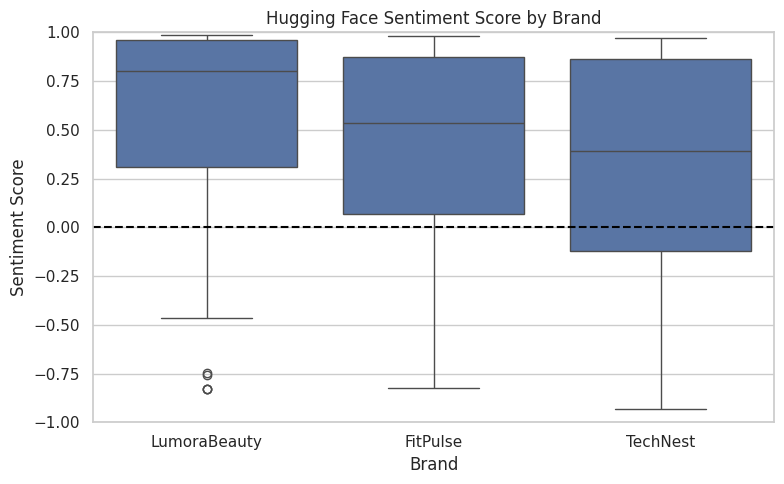

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Brand", y="Sentiment_Score")
plt.axhline(0, color="black", linestyle="--")
plt.ylim(-1, 1)
plt.title("Hugging Face Sentiment Score by Brand")
plt.xlabel("Brand")
plt.ylabel("Sentiment Score")
plt.tight_layout()
plt.show()

### 6. Hugging Face vs VADER Robustness Check

This checks whether the transformer model and VADER tell a similar story. If both methods rank brands similarly, the sentiment finding is more robust. If they differ, use the example posts to decide which method looks more plausible for this dataset.

Correlation between Hugging Face and VADER sentiment:


,Sentiment_Score,VADER_Compound
Sentiment_Score,1.000,0.536
VADER_Compound,0.536,1.000


Average sentiment by brand, using both methods:


,Sentiment_Score,VADER_Compound
Brand,,
FitPulse,0.435,0.217
LumoraBeauty,0.614,0.561
TechNest,0.286,0.251


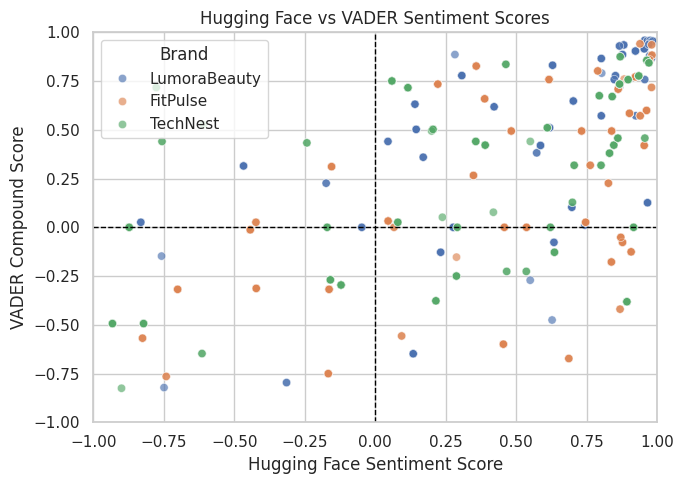

In [ ]:
print("Correlation between Hugging Face and VADER sentiment:")
display(df[["Sentiment_Score", "VADER_Compound"]].corr().round(3))

print("Average sentiment by brand, using both methods:")
display(df.groupby("Brand")[["Sentiment_Score", "VADER_Compound"]].mean().round(3))

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Sentiment_Score", y="VADER_Compound", hue="Brand", alpha=0.65)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.title("Hugging Face vs VADER Sentiment Scores")
plt.xlabel("Hugging Face Sentiment Score")
plt.ylabel("VADER Compound Score")
plt.tight_layout()
plt.show()

### 7. Check Very Positive and Very Low Sentiment Posts

Use these examples to judge whether the transformer model's score makes sense.

In [ ]:
print("Most positive posts:")
display(df.nlargest(5, "Sentiment_Score")[["Post_ID", "Brand", "HF_Sentiment_Label", "Sentiment_Score", "HF_Positive_Prob", "HF_Negative_Prob", "VADER_Compound", "Post_Text"]])

print("Lowest sentiment posts:")
display(df.nsmallest(5, "Sentiment_Score")[["Post_ID", "Brand", "HF_Sentiment_Label", "Sentiment_Score", "HF_Positive_Prob", "HF_Negative_Prob", "VADER_Compound", "Post_Text"]])

Most positive posts:


,Post_ID,Brand,HF_Sentiment_Label,Sentiment_Score,HF_Positive_Prob,HF_Negative_Prob,VADER_Compound,Post_Text
7,8,LumoraBeauty,Positive,0.986542,0.988383,0.001841,0.9538,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌
73,74,LumoraBeauty,Positive,0.986542,0.988383,0.001841,0.9538,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌
95,96,LumoraBeauty,Positive,0.986542,0.988383,0.001841,0.9538,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌
31,32,LumoraBeauty,Positive,0.986542,0.988383,0.001841,0.9538,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌
33,34,LumoraBeauty,Positive,0.984576,0.987825,0.003249,0.9551,That feeling when your concealer matches perfectly 💯😍 Screenshot this if your Lumora shade was spot on! We love your foundation stories 🎨💕


Lowest sentiment posts:


,Post_ID,Brand,HF_Sentiment_Label,Sentiment_Score,HF_Positive_Prob,HF_Negative_Prob,VADER_Compound,Post_Text
421,422,TechNest,Negative,-0.931963,0.006943,0.938906,-0.4939,Genuinely frustrated by how quickly premium smartphones become unsupported 😤📱 You paid over 1000 euros for 3 years of updates. The industry needs to do bett...
597,598,TechNest,Negative,-0.931963,0.006943,0.938906,-0.4939,Genuinely frustrated by how quickly premium smartphones become unsupported 😤📱 You paid over 1000 euros for 3 years of updates. The industry needs to do bett...
444,445,TechNest,Negative,-0.931963,0.006943,0.938906,-0.4939,Genuinely frustrated by how quickly premium smartphones become unsupported 😤📱 You paid over 1000 euros for 3 years of updates. The industry needs to do bett...
475,476,TechNest,Negative,-0.931963,0.006943,0.938906,-0.4939,Genuinely frustrated by how quickly premium smartphones become unsupported 😤📱 You paid over 1000 euros for 3 years of updates. The industry needs to do bett...
489,490,TechNest,Negative,-0.931963,0.006943,0.938906,-0.4939,Genuinely frustrated by how quickly premium smartphones become unsupported 😤📱 You paid over 1000 euros for 3 years of updates. The industry needs to do bett...


### Methodological Notes and Limitations

The Hugging Face model is more suitable than a general lexicon tool because it is trained for social-media-style sentiment, but it is still not perfect. VADER is included as a lightweight robustness check. Both methods may still miss sarcasm, emojis, slang, and brand-specific context. For example, a product post might mention a negative problem such as blemishes or slow devices while actually making a positive product claim.

### 8. Save the Q1 Dataset

This creates a new CSV with the Hugging Face and VADER sentiment scores added. We can use this file later for Q4.

In [ ]:
df.to_csv("Team_Assignment_2_Q1_with_sentiment.csv", index=False, encoding="utf-8-sig")

print("Saved: Team_Assignment_2_Q1_with_sentiment.csv")

Saved: Team_Assignment_2_Q1_with_sentiment.csv


# **Q2 — Topic Classification: What Are Brands Posting About?**

The objective is to classify each brand social media post into one of three intent categories:

- **Informative**
- **Entertaining**
- **Promotional**

We use a **zero-shot classification pipeline from Hugging Face Transformers**. The input text is the `Post_Text` column, which contains the full social media post including emojis.

The final output of this notebook will be a new column called `Topic_Class`, which stores the predicted intent category for each post and will later be used as a predictor in Q4.

### Methodological Plan
1. Classify each post as `Informative`, `Entertaining`, or `Promotional`.
2. Report the topic distribution overall and by brand.
3. Identify the most promotional and most informative brand.
4. Inspect selected posts to assess whether the classification is plausible.
5. Save the predicted topic class as a new column for Q4.

### Topic classification

In [ ]:

from transformers import pipeline
import torch

# Check whether Colab is using GPU or CPU
device = 0 if torch.cuda.is_available() else -1

print("GPU available:", torch.cuda.is_available())
print("Device used:", "GPU" if device == 0 else "CPU")

# Labels required by the assignment
candidate_labels = [
    "Informative",
    "Entertaining",
    "Promotional"
]

# Load zero-shot classification pipeline
classifier = pipeline(
    "zero-shot-classification",
    model="cross-encoder/nli-deberta-v3-small",
    device=device
)

print("Zero-shot classifier loaded successfully.")
print("Candidate labels:", candidate_labels)

GPU available: True
Device used: GPU


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/568M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: cross-encoder/nli-deberta-v3-small
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

Zero-shot classifier loaded successfully.
Candidate labels: ['Informative', 'Entertaining', 'Promotional']


In [ ]:
from tqdm.notebook import tqdm

tqdm.pandas()

# Function to classify a single post
def classify_topic(text):

    # Safety check for missing or empty text
    if pd.isna(text) or str(text).strip() == "":
        return "Unknown"

    result = classifier(
        str(text),
        candidate_labels
    )

    return result["labels"][0]

# Apply classifier to all posts
print("Running zero-shot classification...")

df["Topic_Class"] = df["Post_Text"].progress_apply(classify_topic)

print("\nClassification completed.")

# Show results
display(df[["Brand", "Post_Text", "Topic_Class"]].head(10))

Running zero-shot classification...


  0%|          | 0/600 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Classification completed.


,Brand,Post_Text,Topic_Class
0,LumoraBeauty,"The order matters! Skincare layering: cleanser, toner, serum, eye cream, moisturiser, SPF (AM) or facial oil (PM) 🌸 Save this post for your next routine ref...",Informative
1,LumoraBeauty,Current mood: applying a sheet mask and pretending it is a luxury spa day 🧖🥂 Anyone else? Drop a 🙋 if self-care Sunday is sacred to you!,Informative
2,LumoraBeauty,Your skin deserves a standing ovation today 👏✨ Drop a compliment for a fellow skincare lover below. Good vibes only in Lumora comments! 💛🌸,Entertaining
3,LumoraBeauty,"Our ClearCalm Blemish Serum has over 10,000 five-star reviews 🙌⭐ Visible results in 72 hours or your money back. Try it risk-free. Link in bio 💚✨",Informative
4,LumoraBeauty,"Retinol 101 🧪 Start with 0.25% twice a week at night, always follow with SPF the next morning. Our Lumora Night Renewal Serum is perfect for beginners ✨🌙",Informative
5,LumoraBeauty,AHA vs BHA: AHAs (like glycolic acid) resurface the top layer for glow and texture 🌟 BHAs (like salicylic acid) go deeper into pores for blemish control 🧴 B...,Informative
6,LumoraBeauty,Skincare personality test 🧴 Are you a 3-step minimalist or a full 10-step devotee? No wrong answers 👇,Informative
7,LumoraBeauty,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌,Promotional
8,LumoraBeauty,LIMITED TIME ✨ Buy any 2 Lumora skincare products and receive our Rose Glow face mask FREE 🌸🎁 Offer ends Sunday. Link in bio to grab yours! 💕,Promotional
9,LumoraBeauty,"If your skincare routine had a soundtrack, what would it be? 🎵✨ Ours would be slow, luxurious and a little glittery 💫💛 Let us know below!",Informative


### Overall Distribution of Predicted Topic Classes

We first examine the distribution of predicted topic classes across all 600 posts.

This directly answers the first reporting requirement of Q2: showing how many posts are classified as `Informative`, `Entertaining`, or `Promotional` across the full dataset.

Both counts and percentages are reported, because counts show the absolute volume of content while percentages make the relative communication strategy easier to interpret.

Overall distribution of predicted topic classes:


,Number_of_Posts,Percentage
Topic_Class,,
Informative,411,68.5
Entertaining,45,7.5
Promotional,144,24.0


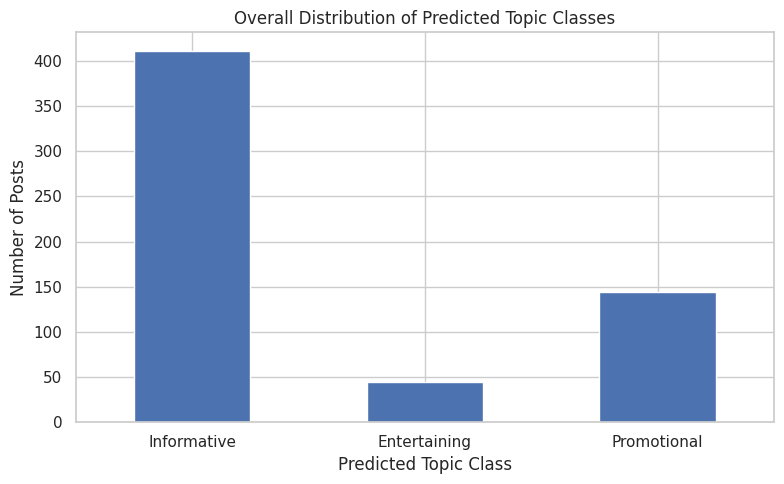

In [ ]:
# Fixed order required by the assignment
topic_order = ["Informative", "Entertaining", "Promotional"]

# Counts
overall_topic_counts = (
    df["Topic_Class"]
    .value_counts()
    .reindex(topic_order, fill_value=0)
)

# Percentages
overall_topic_percentages = (
    df["Topic_Class"]
    .value_counts(normalize=True)
    .reindex(topic_order, fill_value=0) * 100
)

# Final table
overall_topic_distribution = pd.DataFrame({
    "Number_of_Posts": overall_topic_counts,
    "Percentage": overall_topic_percentages.round(1)
})

print("Overall distribution of predicted topic classes:")
display(overall_topic_distribution)

# Visualisation
plt.figure(figsize=(8, 5))
overall_topic_distribution["Number_of_Posts"].plot(kind="bar")

plt.title("Overall Distribution of Predicted Topic Classes")
plt.xlabel("Predicted Topic Class")
plt.ylabel("Number of Posts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation of Overall Topic Distribution

The zero-shot classifier predicts that most posts in the dataset are `Informative`.

Specifically:

- 411 posts (68.5%) are classified as Informative
- 144 posts (24.0%) are classified as Promotional
- only 45 posts (7.5%) are classified as Entertaining

This suggests that the brands primarily focus on educational and informational communication strategies rather than purely entertainment-oriented content.

The relatively high share of Informative posts is plausible because many social media posts in skincare, fitness and technology marketing explain product usage, provide recommendations, or share practical advice.

Promotional content is also common, but less dominant than informational content. This indicates that brands are not relying exclusively on direct advertising, but instead combine promotion with educational messaging.

Entertaining content represents the smallest category. This may indicate that the brands prioritise trust-building and product communication over meme-style or purely engagement-driven posts.

Topic distribution by brand:


Topic_Class,Informative,Entertaining,Promotional
Brand,,,
FitPulse,145,6,49
LumoraBeauty,129,18,53
TechNest,137,21,42



Topic distribution by brand (%):


Topic_Class,Informative,Entertaining,Promotional
Brand,,,
FitPulse,72.5,3.0,24.5
LumoraBeauty,64.5,9.0,26.5
TechNest,68.5,10.5,21.0


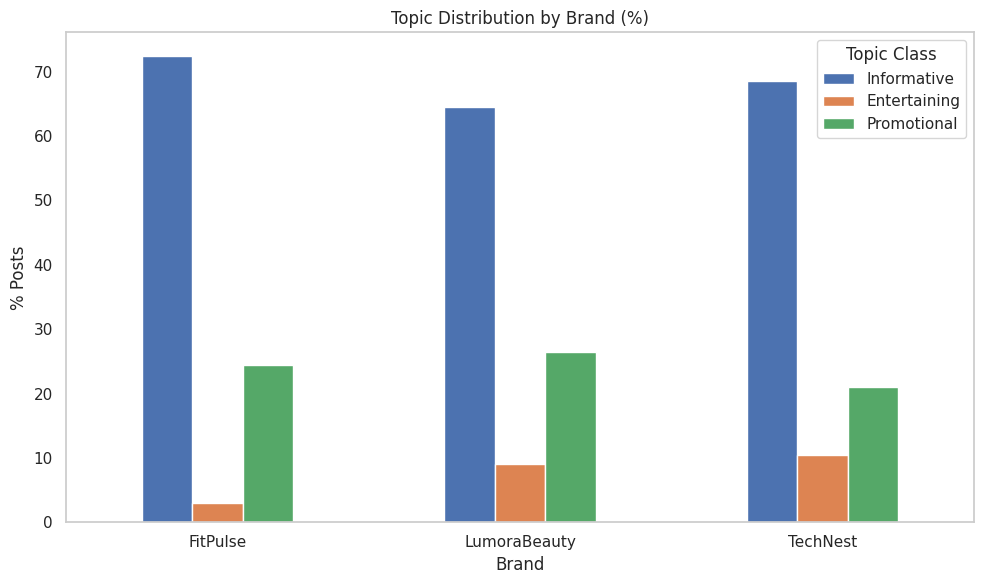

In [ ]:
# Cross-tabulation
brand_topic_distribution = pd.crosstab(
    df["Brand"],
    df["Topic_Class"]
)

# Reorder columns
brand_topic_distribution = brand_topic_distribution.reindex(
    columns=["Informative", "Entertaining", "Promotional"],
    fill_value=0
)

print("Topic distribution by brand:")
display(brand_topic_distribution)

# Percentage version
brand_topic_percentages = pd.crosstab(
    df["Brand"],
    df["Topic_Class"],
    normalize="index"
) * 100

brand_topic_percentages = brand_topic_percentages.reindex(
    columns=["Informative", "Entertaining", "Promotional"],
    fill_value=0
)

print("\nTopic distribution by brand (%):")
display(brand_topic_percentages.round(1))

# Plot percentages
brand_topic_percentages.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Topic Distribution by Brand (%)")
plt.xlabel("Brand")
plt.ylabel("% Posts")
plt.xticks(rotation=0)
plt.legend(title="Topic Class")
plt.grid(False) # Removed grid lines
plt.tight_layout()
plt.show()

### Interpretation of Topic Distribution by Brand

The topic distribution differs across brands, suggesting different communication strategies.

`FitPulse` is the most informative brand, with 72.5% of posts classified as Informative. This suggests that the brand focuses heavily on educational fitness content, advice, and practical recommendations.

`LumoraBeauty` publishes the highest proportion of Promotional posts (26.5%). This is plausible because skincare and beauty brands frequently promote products, routines, discounts, and product launches.

`TechNest` has the highest proportion of Entertaining posts (10.5%). Compared to the other brands, its communication style appears slightly more engagement-oriented and community-driven.

Despite these differences, all three brands rely primarily on Informative content, indicating that educational communication is the dominant strategy across the dataset.

In [ ]:
# 9. Plausibility check of classifications


print("Sample classified posts:\n")

sample_posts = df[
    ["Brand", "Post_Text", "Topic_Class"]
].sample(12, random_state=42)

display(sample_posts)

df[(df["Topic_Class"]=="Promotional") & (df["Brand"]=="LumoraBeauty") ].head()

Sample classified posts:



,Brand,Post_Text,Topic_Class
110,LumoraBeauty,Physical exfoliants use particles to buff skin. Chemical exfoliants (AHAs/BHAs) dissolve dead cells at a molecular level. Both are valid depending on your s...,Informative
419,TechNest,Nothing hits like a clean desk setup ✨🖥️ Show us your workstation. We are sharing the best ones in our stories this weekend 📸💻 Drop a pic in the comments! 👇,Informative
565,TechNest,PCIe 5.0 SSDs are now available but current real-world performance gains over PCIe 4.0 are minimal for most users. The technology will matter more as softwa...,Informative
77,LumoraBeauty,Current mood: applying a sheet mask and pretending it is a luxury spa day 🧖🥂 Anyone else? Drop a 🙋 if self-care Sunday is sacred to you!,Informative
181,LumoraBeauty,Introducing our bestselling Lumora Glow Serum now in a new 50ml size 🎉✨ Packed with 15% Vitamin C and hyaluronic acid for lit-from-within radiance. Shop now...,Promotional
284,FitPulse,"Hydration for athletes 💧 500ml before exercise, sip during, replenish 150% of fluids lost after. Dehydration of just 2% can impair performance by up to 20% ⚡",Promotional
10,LumoraBeauty,That awkward moment when you realise you have been layering your serums in the completely wrong order for 6 months 😬 Been there. No judgement 🤝,Promotional
469,TechNest,"Tech people have two moods: this is the most elegant solution I have ever seen, and who wrote this code 😂💻 Drop your latest reaction below 👇⚡",Informative
78,LumoraBeauty,Hot take: your 10-minute nighttime routine is more powerful than any hour-long spa treatment 💆✨ Agree or disagree? Tell us your night routine 👇🌙,Informative
349,FitPulse,"Watching your form improve over months of consistent training hits different 🎯💪 It is not just the muscles. It is the discipline, the belief in yourself. Th...",Informative


,Post_ID,Brand,Handle,Post_Text,Total_Followers,Total_Posts_LastYear,Num_Likes,Num_Comments,Num_Reposts,Text_Length,HF_Negative_Prob,HF_Neutral_Prob,HF_Positive_Prob,Sentiment_Score,HF_Sentiment_Label,VADER_Compound,Topic_Class
7,8,LumoraBeauty,@LumoraBeauty,Glow-up season is every season with Lumora 🌸✨ Show us your before and after. We love celebrating YOUR progress 💕🙌,485000,318,5783,70,1119,113,0.001841,0.009777,0.988383,0.986542,Positive,0.9538,Promotional
8,9,LumoraBeauty,@LumoraBeauty,LIMITED TIME ✨ Buy any 2 Lumora skincare products and receive our Rose Glow face mask FREE 🌸🎁 Offer ends Sunday. Link in bio to grab yours! 💕,485000,318,3769,83,323,141,0.001627,0.073647,0.924726,0.923099,Positive,0.9041,Promotional
10,11,LumoraBeauty,@LumoraBeauty,That awkward moment when you realise you have been layering your serums in the completely wrong order for 6 months 😬 Been there. No judgement 🤝,485000,318,1204,104,116,143,0.770164,0.208601,0.021235,-0.748929,Negative,-0.8221,Promotional
11,12,LumoraBeauty,@LumoraBeauty,LIMITED TIME ✨ Buy any 2 Lumora skincare products and receive our Rose Glow face mask FREE 🌸🎁 Offer ends Sunday. Link in bio to grab yours! 💕,485000,318,2801,352,573,141,0.001627,0.073647,0.924726,0.923099,Positive,0.9041,Promotional
12,13,LumoraBeauty,@LumoraBeauty,Introducing our bestselling Lumora Glow Serum now in a new 50ml size 🎉✨ Packed with 15% Vitamin C and hyaluronic acid for lit-from-within radiance. Shop now...,485000,318,3665,188,412,175,0.001642,0.042320,0.956037,0.954395,Positive,0.9153,Promotional


### Plausibility Check of Topic Classification

The predicted classifications generally appear plausible.

Posts classified as `Informative` typically contain educational explanations, practical advice, or technical information. For example, several skincare and fitness posts explain product usage, health recommendations, or technological differences in detail.

`Promotional` posts usually contain clear marketing language such as “shop now”, “limited edition”, “link in bio”, or direct product promotion. These classifications appear highly consistent with the intended category.

Some posts classified as `Entertaining` or `Informative` are slightly ambiguous because social media content often combines multiple intentions simultaneously. For instance, interactive posts asking users to comment or share experiences may also contain informative elements.

This highlights an important limitation of zero-shot classification: each post is forced into a single category even when the content may partially belong to multiple classes. Nevertheless, the overall classification quality appears coherent and suitable for exploratory social media analysis.

### Methodological Notes and Limitations

This analysis uses a zero-shot classification approach based on Hugging Face Transformers. The model predicts the most likely intent category for each post without requiring manually labeled training data.

The approach is efficient and scalable for exploratory NLP analysis, especially when labeled datasets are unavailable. However, several limitations should be acknowledged.

First, social media posts often combine multiple intentions simultaneously (e.g., informative and promotional content), while the classifier assigns only one label per post.

Second, emojis, slang, hashtags, and short-form social media language may introduce ambiguity and affect classification accuracy.

Third, zero-shot models rely on semantic similarity rather than domain-specific training, meaning that some classifications may not perfectly reflect the intended marketing strategy.

Despite these limitations, the results provide a coherent overview of brand communication styles and generate meaningful features for downstream analysis in Q4.

In [ ]:
# 10. Save dataset with Topic_Class for Q4

output_file = "Team_Assignment_2_Data_2026_Q2_Topic_Class.csv"

df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("Dataset successfully saved.")
print("Saved file:", output_file)

Dataset successfully saved.
Saved file: Team_Assignment_2_Data_2026_Q2_Topic_Class.csv


In [ ]:
import os

print(os.getcwd())
print("\nFiles in current directory:\n")

for file in os.listdir():
    print(file)

/content

Files in current directory:

.config
Team Assignment 2 Data 2026.csv
PARA_Results.csv
Team_Assignment_2_Data_2026_Q2_Topic_Class.csv
Team_Assignment_2_Q1_with_sentiment.csv
sample_data


# **Q3 — Paralinguistic/Emoji Analysis**

## A. Using Pandas library

In [ ]:
# Install the emoji library
%pip install -q emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 16.4 MB/s eta 0:00:00


In [ ]:
import emoji

# Function to extract emoji count and demojized text
def extract_emoji_data(text):
    # Count emojis
    emoji_count = emoji.emoji_count(text)

    # Get demojized text. This will replace emojis with their textual descriptions (e.g., ':smiling_face:').
    # We then extract these descriptions to represent 'Emoji_type'.
    demojized_text = emoji.demojize(text)

    # Find all demojized emoji names
    emoji_names = [e for e in emoji.EMOJI_DATA if e in text]
    demojized_emoji_names = [emoji.demojize(e) for e in emoji_names]

    return emoji_count, demojized_emoji_names

# Apply the function to the 'Post_Text' column
df[['Emoji_count', 'Emoji_types_list']] = df['Post_Text'].apply(lambda x: pd.Series(extract_emoji_data(x)))

# The emoji library does not provide direct sentiment for emojis.
# We will proceed with the other requested analyses.

print("DataFrame with new emoji columns:")
display(df[['Post_ID', 'Brand', 'Post_Text', 'Emoji_count', 'Emoji_types_list']].head())

DataFrame with new emoji columns:


,Post_ID,Brand,Post_Text,Emoji_count,Emoji_types_list
0,1,LumoraBeauty,"The order matters! Skincare layering: cleanser, toner, serum, eye cream, moisturiser, SPF (AM) or facial oil (PM) 🌸 Save this post for your next routine ref...",2,"[:cherry_blossom:, :yellow_heart:]"
1,2,LumoraBeauty,Current mood: applying a sheet mask and pretending it is a luxury spa day 🧖🥂 Anyone else? Drop a 🙋 if self-care Sunday is sacred to you!,3,"[:clinking_glasses:, :person_in_steamy_room:, :person_raising_hand:]"
2,3,LumoraBeauty,Your skin deserves a standing ovation today 👏✨ Drop a compliment for a fellow skincare lover below. Good vibes only in Lumora comments! 💛🌸,4,"[:cherry_blossom:, :clapping_hands:, :sparkles:, :yellow_heart:]"
3,4,LumoraBeauty,"Our ClearCalm Blemish Serum has over 10,000 five-star reviews 🙌⭐ Visible results in 72 hours or your money back. Try it risk-free. Link in bio 💚✨",4,"[:green_heart:, :raising_hands:, :sparkles:, :star:]"
4,5,LumoraBeauty,"Retinol 101 🧪 Start with 0.25% twice a week at night, always follow with SPF the next morning. Our Lumora Night Renewal Serum is perfect for beginners ✨🌙",3,"[:crescent_moon:, :sparkles:, :test_tube:]"


In [ ]:
# Create a frequency table of emoji types per brand

# Explode the list of emoji types so each emoji gets its own row
emoji_df = df.explode('Emoji_types_list')

# Filter out rows where there are no emojis (empty strings or None after explode)
emoji_df = emoji_df[emoji_df['Emoji_types_list'].astype(bool)]

# Group by brand and emoji type, then count occurrences
emoji_frequency_per_brand = emoji_df.groupby(['Brand', 'Emoji_types_list']).size().reset_index(name='Frequency')

# Pivot the table for better readability
emoji_frequency_pivot = emoji_frequency_per_brand.pivot_table(index='Emoji_types_list', columns='Brand', values='Frequency', fill_value=0)

print("Frequency of emoji types per brand:")
display(emoji_frequency_pivot.sort_values(by=emoji_frequency_pivot.columns.tolist(), ascending=False).head(20)) # Display top 20 frequent emojis

Frequency of emoji types per brand:


Brand,FitPulse,LumoraBeauty,TechNest
Emoji_types_list,,,
:flexed_biceps:,93.0,3.0,0.0
:fire:,44.0,0.0,14.0
:backhand_index_pointing_down:,42.0,18.0,51.0
:couch_and_lamp:,28.0,0.0,0.0
:warning:,22.0,14.0,42.0
:face_with_tears_of_joy:,22.0,5.0,27.0
:grinning_face_with_sweat:,20.0,9.0,14.0
:person_lifting_weights:,18.0,0.0,0.0
:prohibited:,14.0,0.0,4.0


### 1. Which Brand Uses the Most Emojis on Average? Which Uses the Fewest?

In [ ]:
emoji_avg_per_brand = df.groupby('Brand')['Emoji_count'].mean().sort_values(ascending=False)

print("Average emoji count per brand:")
display(emoji_avg_per_brand)

most_emojis_brand = emoji_avg_per_brand.index[0]
most_emojis_count = emoji_avg_per_brand.iloc[0]
fewest_emojis_brand = emoji_avg_per_brand.index[-1]
fewest_emojis_count = emoji_avg_per_brand.iloc[-1]

print(f"\n{most_emojis_brand} uses the most emojis on average with {most_emojis_count:.2f} emojis per post.")
print(f"{fewest_emojis_brand} uses the fewest emojis on average with {fewest_emojis_count:.2f} emojis per post.")

Average emoji count per brand:


,Emoji_count
Brand,
TechNest,2.56
LumoraBeauty,2.44
FitPulse,2.30



TechNest uses the most emojis on average with 2.56 emojis per post.
FitPulse uses the fewest emojis on average with 2.30 emojis per post.


### 2. Are Certain Emojis Distinctive to One Brand or Topic Category?

In [ ]:
# To identify distinctive emojis, we can look at emojis that are highly frequent for one brand
# but less so for others. We can normalize the frequencies by brand to see relative usage.

emoji_frequency_normalized = emoji_frequency_pivot.div(emoji_frequency_pivot.sum(axis=0), axis=1)

print("Top 5 distinctive emojis for each brand (based on highest relative frequency within brand):")

for brand in emoji_frequency_normalized.columns:
    print(f"\n--- {brand} ---")
    display(emoji_frequency_normalized.nlargest(5, brand)[[brand]])

print("\nObservation: The frequency table shows some emojis appear more often for specific brands.")
print("For example, 'sparkles' ✨ and 'flower' 🌸 seem more associated with LumoraBeauty, 'flexed_biceps' 💪 and 'house' 🏠 with FitPulse, and 'zap' ⚡ or 'laptop' 💻 with TechNest.")
print("This suggests that emojis are indeed used in a distinctive way by brands to align with their topic categories (beauty, fitness, tech).")

Top 5 distinctive emojis for each brand (based on highest relative frequency within brand):

--- FitPulse ---


Brand,FitPulse
Emoji_types_list,
:flexed_biceps:,0.187123
:fire:,0.088531
:backhand_index_pointing_down:,0.084507
:couch_and_lamp:,0.056338
:face_with_tears_of_joy:,0.044266



--- LumoraBeauty ---


Brand,LumoraBeauty
Emoji_types_list,
:sparkles:,0.168986
:yellow_heart:,0.105368
:cherry_blossom:,0.091451
:two_hearts:,0.039761
:crescent_moon:,0.037773



--- TechNest ---


Brand,TechNest
Emoji_types_list,
:laptop:,0.110915
:high_voltage:,0.109155
:backhand_index_pointing_down:,0.089789
:desktop_computer:,0.084507
:warning:,0.073944



Observation: The frequency table shows some emojis appear more often for specific brands.
For example, 'sparkles' ✨ and 'flower' 🌸 seem more associated with LumoraBeauty, 'flexed_biceps' 💪 and 'house' 🏠 with FitPulse, and 'zap' ⚡ or 'laptop' 💻 with TechNest.
This suggests that emojis are indeed used in a distinctive way by brands to align with their topic categories (beauty, fitness, tech).


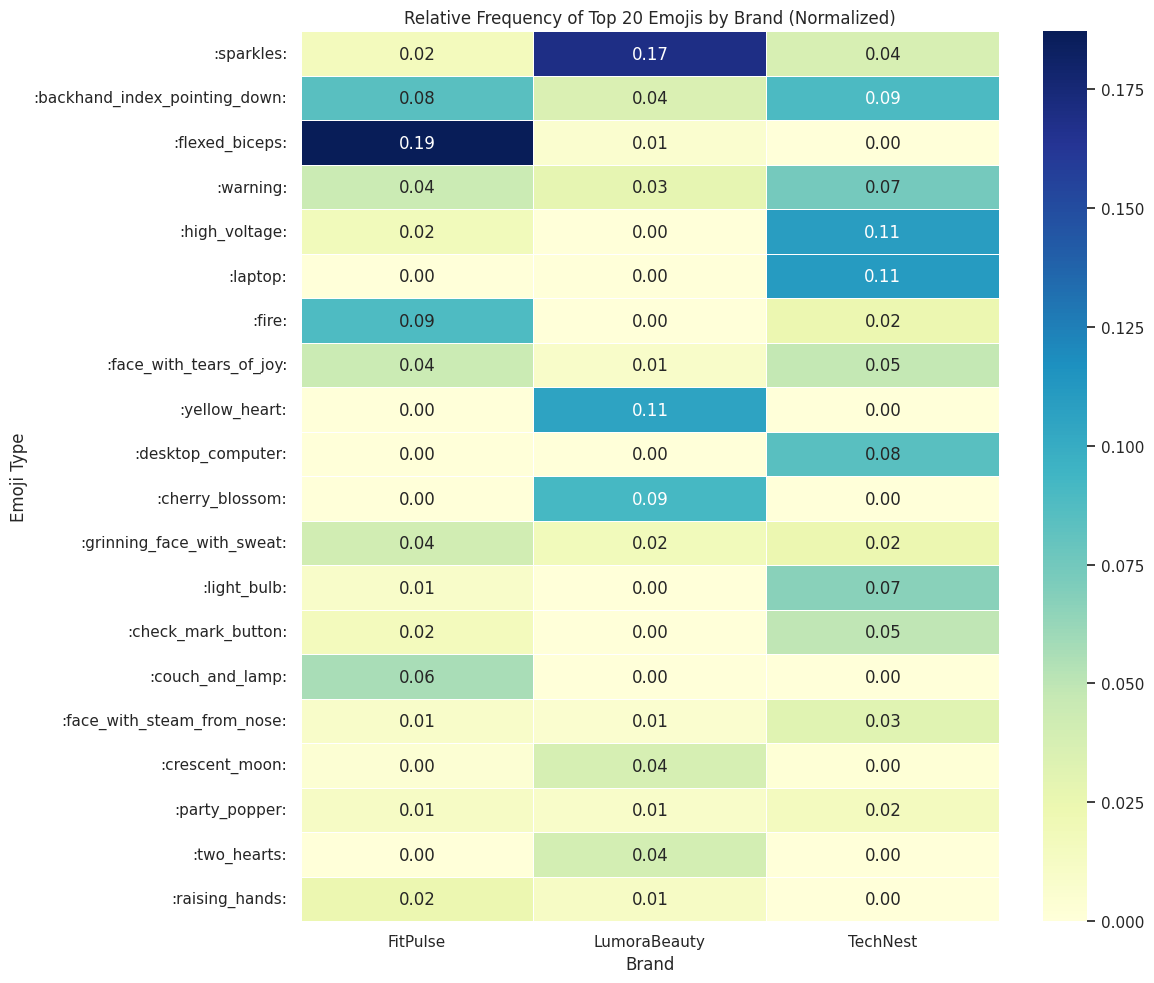

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the total frequency of each emoji across all brands
total_emoji_frequency = emoji_frequency_pivot.sum(axis=1).sort_values(ascending=False)

# Select the top 20 most frequent emojis
top_emojis = total_emoji_frequency.head(20).index

# Filter the normalized frequency DataFrame for these top emojis
filtered_emoji_frequency_normalized = emoji_frequency_normalized.loc[top_emojis]

plt.figure(figsize=(12, 10))
sns.heatmap(filtered_emoji_frequency_normalized, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=.5)
plt.title('Relative Frequency of Top 20 Emojis by Brand (Normalized)')
plt.xlabel('Brand')
plt.ylabel('Emoji Type')
plt.tight_layout()
plt.show()

The heatmap visually confirms that certain emojis are indeed distinctive to particular brands.

For example:
- **LumoraBeauty** shows higher relative frequencies for emojis like 'yellow_heart', 'sparkles', and 'cherry_blossom', which align with beauty and skincare themes.
- **FitPulse** stands out with 'flexed_biceps', 'backhand_index_pointing_down', and 'house', reflecting fitness and home workout content.
- **TechNest** shows distinctiveness with emojis such as 'high_voltage', 'warning', and 'robot', consistent with technology-related topics.

This suggests that brands strategically use emojis that resonate with their specific product categories and communication styles, contributing to their brand identity.

### 3. Is There a Correlation Between Emoji Count and Sentiment Score?

Correlation between Emoji_count and Sentiment_Score: 0.373


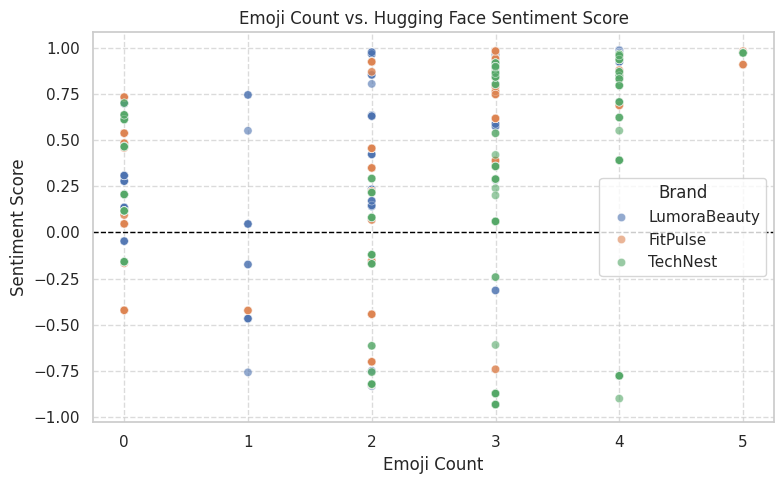


Observation: A correlation coefficient close to 0 (positive or negative) indicates a weak linear relationship. A scatter plot can further illustrate if there's any visible pattern.
Based on the correlation coefficient, we can determine the strength and direction of the linear relationship between emoji count and sentiment score.


In [ ]:
correlation = df['Emoji_count'].corr(df['Sentiment_Score'])

print(f"Correlation between Emoji_count and Sentiment_Score: {correlation:.3f}")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Emoji_count', y='Sentiment_Score', hue='Brand', alpha=0.6)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Emoji Count vs. Hugging Face Sentiment Score')
plt.xlabel('Emoji Count')
plt.ylabel('Sentiment Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nObservation: A correlation coefficient close to 0 (positive or negative) indicates a weak linear relationship. A scatter plot can further illustrate if there's any visible pattern.")
print("Based on the correlation coefficient, we can determine the strength and direction of the linear relationship between emoji count and sentiment score.")

## B. Using PARA

In [ ]:
df_para = pd.read_csv("PARA_Results.csv", encoding="utf-8-sig")


### 1. Which Brand Uses the Most / Fewest Emojis?

,Avg_Emoji_Count,Median_Emoji_Count,Avg_Bodily_Emoji,Avg_Nonbodily_Emoji,Avg_Tactile_Emoji,Avg_TPL_Index
Brand,,,,,,
TechNest,2.56,3.0,0.61,1.95,0.00,2.70
LumoraBeauty,2.44,3.0,0.49,1.94,0.00,2.62
FitPulse,2.30,2.0,1.16,1.12,0.01,2.38



TechNest uses the most emojis on average (2.56 per post)
FitPulse uses the fewest emojis on average (2.30 per post)


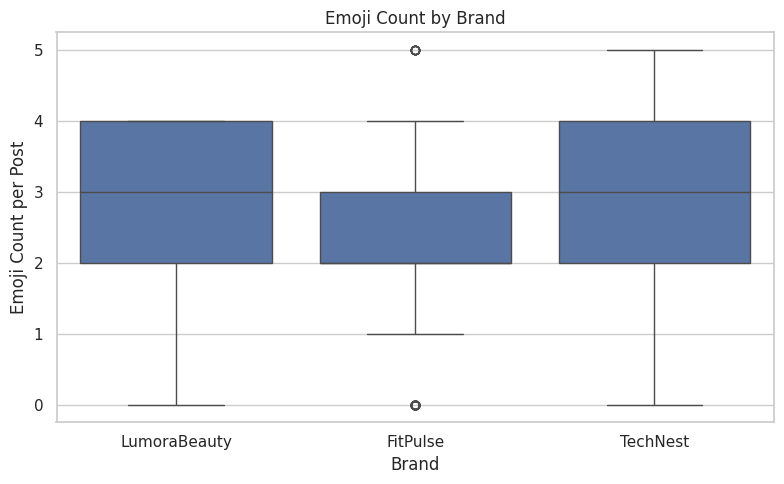

In [ ]:


emoji_by_brand = df_para.groupby("Brand").agg(
    Avg_Emoji_Count=("Emoji_Count", "mean"),
    Median_Emoji_Count=("Emoji_Count", "median"),
    Avg_Bodily_Emoji=("Bodily_Emoji", "mean"),
    Avg_Nonbodily_Emoji=("Nonbodily_Emoji", "mean"),
    Avg_Tactile_Emoji=("Tactile_Emoji", "mean"),
    Avg_TPL_Index=("TPL_Index", "mean"),
).round(2).sort_values("Avg_Emoji_Count", ascending=False)

display(emoji_by_brand)

most = emoji_by_brand.index[0]
fewest = emoji_by_brand.index[-1]
print(f"\n{most} uses the most emojis on average ({emoji_by_brand.loc[most, 'Avg_Emoji_Count']:.2f} per post)")
print(f"{fewest} uses the fewest emojis on average ({emoji_by_brand.loc[fewest, 'Avg_Emoji_Count']:.2f} per post)")

# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_para, x="Brand", y="Emoji_Count")
plt.title("Emoji Count by Brand")
plt.xlabel("Brand")
plt.ylabel("Emoji Count per Post")
plt.tight_layout()
plt.show()

### 2. Are Certain Emoji Types Distinctive to Each Brand?

,Tactile_Emoji,Bodily_Emoji,Nonbodily_Emoji
Brand,,,
FitPulse,0.01,1.16,1.12
LumoraBeauty,0.00,0.49,1.94
TechNest,0.00,0.61,1.95


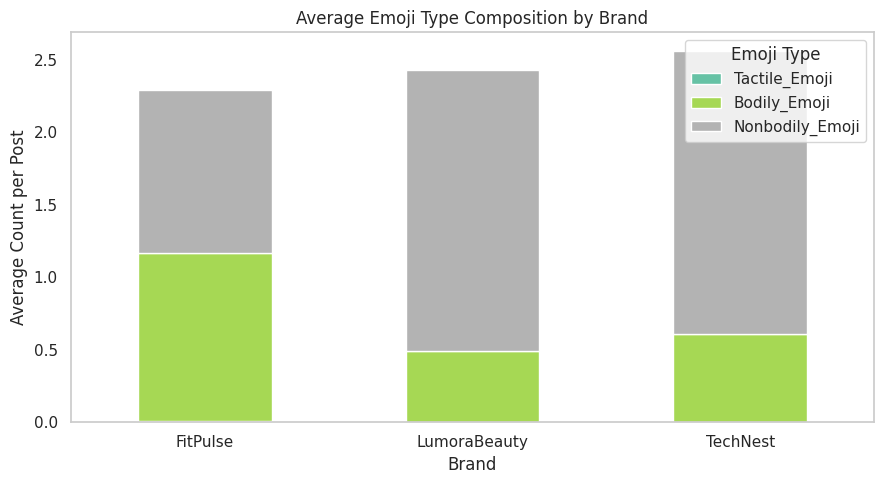

In [ ]:
import matplotlib.pyplot as plt

# Stacked bar: emoji type composition per brand
emoji_type_cols = ["Tactile_Emoji", "Bodily_Emoji", "Nonbodily_Emoji"]

emoji_type_by_brand = df_para.groupby("Brand")[emoji_type_cols].mean().round(2)
display(emoji_type_by_brand)

emoji_type_by_brand.plot(
    kind="bar",
    figsize=(9, 5),
    stacked=True,
    colormap="Set2",
    grid=False # Added to remove the grid
)
plt.title("Average Emoji Type Composition by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Count per Post")
plt.xticks(rotation=0)
plt.legend(title="Emoji Type")
plt.tight_layout()
plt.show()

### 3. Emoji Sentiment: TPL_Index as Paralinguistic Intensity Proxy

,TPL_Mean,TPL_Median,TPL_Std
Brand,,,
FitPulse,2.38,3.0,1.52
LumoraBeauty,2.62,3.0,1.61
TechNest,2.70,3.0,1.56


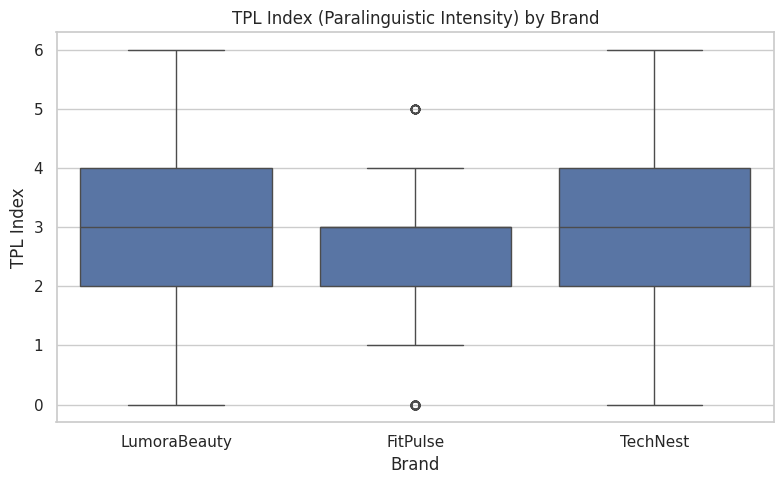

In [ ]:
# PARA does not provide direct emoji valence scores.
# We use TPL_Index (Total Paralanguage Index) as a proxy for overall
# paralinguistic expressiveness, which reflects emotional intensity.

tpl_by_brand = df_para.groupby("Brand")["TPL_Index"].agg(["mean", "median", "std"]).round(2)
tpl_by_brand.columns = ["TPL_Mean", "TPL_Median", "TPL_Std"]
display(tpl_by_brand)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_para, x="Brand", y="TPL_Index")
plt.title("TPL Index (Paralinguistic Intensity) by Brand")
plt.xlabel("Brand")
plt.ylabel("TPL Index")
plt.tight_layout()
plt.show()

### 4. Correlation: Emoji Count vs Sentiment Score

Correlation Emoji_Count vs HF Sentiment_Score: 0.373
Correlation Emoji_Count vs VADER Compound:     0.354


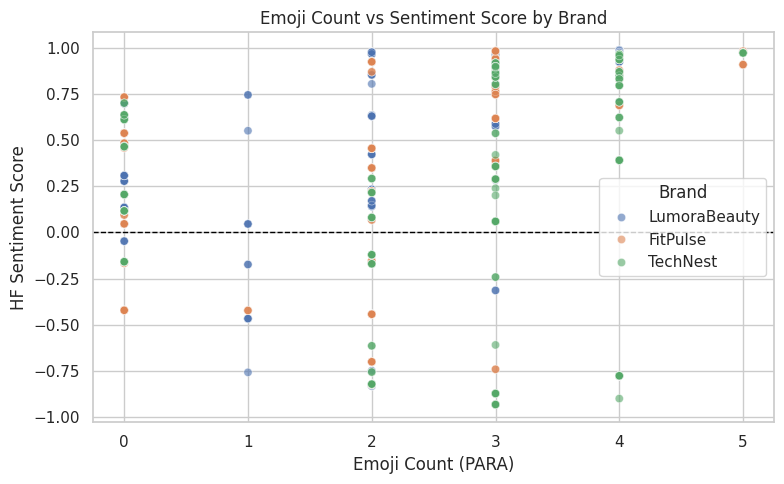

In [ ]:
# Merge with Q1 sentiment scores

df_q1 = pd.read_csv("Team_Assignment_2_Q1_with_sentiment.csv", encoding="utf-8-sig")

sentiment_cols = ["Post_ID", "Sentiment_Score", "VADER_Compound", "HF_Sentiment_Label"]
df_q3 = df_para.merge(df_q1[sentiment_cols], on="Post_ID", how="left")

corr_hf = df_q3["Emoji_Count"].corr(df_q3["Sentiment_Score"])
corr_vader = df_q3["Emoji_Count"].corr(df_q3["VADER_Compound"])

print(f"Correlation Emoji_Count vs HF Sentiment_Score: {corr_hf:.3f}")
print(f"Correlation Emoji_Count vs VADER Compound:     {corr_vader:.3f}")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_q3, x="Emoji_Count", y="Sentiment_Score", hue="Brand", alpha=0.6)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Emoji Count vs Sentiment Score by Brand")
plt.xlabel("Emoji Count (PARA)")
plt.ylabel("HF Sentiment Score")
plt.tight_layout()
plt.show()

### 5. Save Q3 Dataset for Q4

In [ ]:
df_q3.to_csv("Team_Assignment_2_Q3_ready.csv", index=False, encoding="utf-8-sig")
print("Saved: Team_Assignment_2_Q3_ready.csv")

Saved: Team_Assignment_2_Q3_ready.csv


# **Q4 — Drivers of Engagement: What Makes Posts Perform?**

### Merge Q1 + Q2 + Q3 into One Dataset

In [ ]:

import pandas as pd

# Load files
df_q2 = pd.read_csv("Team_Assignment_2_Data_2026_Q2_Topic_Class.csv", encoding="utf-8-sig")
df_q3 = pd.read_csv("Team_Assignment_2_Q3_ready.csv", encoding="utf-8-sig")

# Q3 already has sentiment columns from Q1, so we only need Topic_Class from Q2
df_merged = df_q3.merge(
    df_q2[["Post_ID", "Topic_Class"]],
    on="Post_ID",
    how="left"
)

# Verify
print("Shape:", df_merged.shape)
print("Missing values:\n", df_merged[["Sentiment_Score", "Topic_Class", "Emoji_Count"]].isna().sum())

# Check key columns are present
key_cols = ["Post_ID", "Brand", "Sentiment_Score", "Topic_Class",
            "Emoji_Count", "TPL_Index", "Num_Likes", "Num_Comments"]
display(df_merged[key_cols].head(10))

# Save
df_merged.to_csv("Team_Assignment_2_Q4_ready.csv", index=False, encoding="utf-8-sig")
print("\nSaved: Team_Assignment_2_Q4_ready.csv")

Shape: (600, 36)
Missing values:
 Sentiment_Score    0
Topic_Class        0
Emoji_Count        0
dtype: int64


,Post_ID,Brand,Sentiment_Score,Topic_Class,Emoji_Count,TPL_Index,Num_Likes,Num_Comments
0,1,LumoraBeauty,0.629168,Informative,2,2,2347,69
1,2,LumoraBeauty,0.586299,Informative,3,3,3542,489
2,3,LumoraBeauty,0.970223,Entertaining,4,4,2747,119
3,4,LumoraBeauty,0.956013,Informative,4,4,3185,188
4,5,LumoraBeauty,0.865264,Informative,3,3,1202,229
5,6,LumoraBeauty,0.801957,Informative,3,5,3267,203
6,7,LumoraBeauty,0.141065,Informative,2,2,6068,141
7,8,LumoraBeauty,0.986542,Promotional,4,5,5783,70
8,9,LumoraBeauty,0.923099,Promotional,4,6,3769,83
9,10,LumoraBeauty,0.866213,Informative,4,4,14121,244



Saved: Team_Assignment_2_Q4_ready.csv


### Check for Overdispersion

In [ ]:
for outcome in ["Num_Likes", "Num_Comments"]:
    mean = df[outcome].mean()
    var  = df[outcome].var()
    print(f"{outcome} — Mean: {mean:.1f} | Variance: {var:.1f} | Ratio: {var/mean:.1f}")

Num_Likes — Mean: 2186.7 | Variance: 2903566.5 | Ratio: 1327.8
Num_Comments — Mean: 142.2 | Variance: 16844.1 | Ratio: 118.5


### Prepare Variables

In [ ]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

# Topic dummies (reference: Informative)
df_merged["Topic_Entertaining"] = (df_merged["Topic_Class"] == "Entertaining").astype(int)
df_merged["Topic_Promotional"]  = (df_merged["Topic_Class"] == "Promotional").astype(int)

# Standardize continuous predictors
scaler = StandardScaler()
df_merged[["Sentiment_Score_z", "Emoji_Count_z"]] = scaler.fit_transform(
    df_merged[["Sentiment_Score", "Emoji_Count"]]
)

predictors = [
    "Sentiment_Score_z",
    "Topic_Entertaining",
    "Topic_Promotional",
    "Emoji_Count_z",
]

brands = ["LumoraBeauty", "FitPulse", "TechNest"]

print("Variables ready.")
print(df_merged[predictors].describe().round(2))

# Build design matrix and outcome vectors for whole-dataset models
X        = sm.add_constant(df_merged[predictors])
y_likes   = df_merged["Num_Likes"]
y_comments = df_merged["Num_Comments"]

print("X, y_likes, y_comments are ready for modelling.")


Variables ready.
       Sentiment_Score_z  Topic_Entertaining  Topic_Promotional  Emoji_Count_z
count             600.00              600.00             600.00         600.00
mean                0.00                0.08               0.24           0.00
std                 1.00                0.26               0.43           1.00
min                -2.56                0.00               0.00          -1.71
25%                -0.56                0.00               0.00          -0.30
50%                 0.32                0.00               0.00           0.40
75%                 0.80                0.00               0.00           1.10
max                 1.01                1.00               1.00           1.81
X, y_likes, y_comments are ready for modelling.


### Negative Binomial Model: Num_Likes

In [ ]:
nb_likes = sm.NegativeBinomial(y_likes, X).fit(maxiter=200, disp=False)
print("Negative Binomial — Num_Likes")
print(f"Pseudo R² = {nb_likes.prsquared:.3f}")
print(nb_likes.summary())

Negative Binomial — Num_Likes
Pseudo R² = 0.015
                     NegativeBinomial Regression Results                      
Dep. Variable:              Num_Likes   No. Observations:                  600
Model:               NegativeBinomial   Df Residuals:                      595
Method:                           MLE   Df Model:                            4
Date:                Mon, 11 May 2026   Pseudo R-squ.:                 0.01508
Time:                        17:24:07   Log-Likelihood:                -5066.3
converged:                       True   LL-Null:                       -5143.9
Covariance Type:            nonrobust   LLR p-value:                 1.590e-32
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  7.6188      0.031    244.286      0.000       7.558       7.680
Sentiment_Score_z      0.2866      0.029      9.847      0.

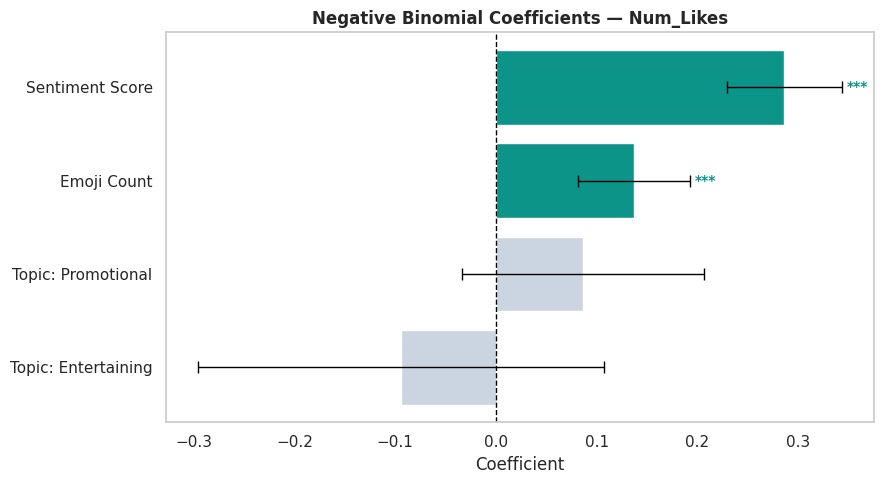

In [ ]:
# Extract coefficients and p-values from the nb_likes model
coef_df = pd.DataFrame({
    "Variable":    nb_likes.params.drop(["const", "alpha"], errors="ignore").index,
    "Coefficient": nb_likes.params.drop(["const", "alpha"], errors="ignore").values,
    "Lower":       nb_likes.conf_int().drop(["const", "alpha"], errors="ignore")[0].values,
    "Upper":       nb_likes.conf_int().drop(["const", "alpha"], errors="ignore")[1].values,
    "p_value":     nb_likes.pvalues.drop(["const", "alpha"], errors="ignore").values
})

# Significance test
coef_df["Significant"] = coef_df["p_value"].apply(
    lambda p: "***" if p < 0.001 else (
              "**"  if p < 0.01  else (
              "*"   if p < 0.05  else "ns"))
)

# Clean variable names
coef_df["Label"] = coef_df["Variable"].map({
    "Sentiment_Score_z":  "Sentiment Score",
    "Topic_Entertaining": "Topic: Entertaining",
    "Topic_Promotional":  "Topic: Promotional",
    "Emoji_Count_z":      "Emoji Count",
})

# Sort by coefficient value
coef_df = coef_df.sort_values("Coefficient")

# Bar colors based on significance
colors = ["#0D9488" if s != "ns" else "#CBD5E1"
          for s in coef_df["Significant"]]

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(coef_df["Label"], coef_df["Coefficient"], color=colors)

# Confidence interval error bars
ax.errorbar(
    coef_df["Coefficient"], coef_df["Label"],
    xerr=[coef_df["Coefficient"] - coef_df["Lower"],
          coef_df["Upper"]       - coef_df["Coefficient"]],
    fmt="none", color="black", capsize=4, linewidth=1
)

# Reference line at zero
ax.axvline(0, color="black", linestyle="--", linewidth=1)

# Add significance stars next to bars
for _, row in coef_df.iterrows():
    if row["Significant"] != "ns":
        xpos = row["Upper"] + 0.005
        ax.text(xpos, row["Label"], row["Significant"],
                va="center", fontsize=10,
                fontweight="bold", color="#0D9488")

ax.set_title("Negative Binomial Coefficients — Num_Likes",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient")
ax.set_ylabel("")
ax.grid(False)
plt.tight_layout()
plt.show()

### Negative Binomial Model: Num_Comments

In [ ]:
nb_comments = sm.NegativeBinomial(y_comments, X).fit(maxiter=200, disp=False)
print("Negative Binomial — Num_Comments")
print(f"Pseudo R² = {nb_comments.prsquared:.3f}")
print(nb_comments.summary())

Negative Binomial — Num_Comments
Pseudo R² = 0.030
                     NegativeBinomial Regression Results                      
Dep. Variable:           Num_Comments   No. Observations:                  600
Model:               NegativeBinomial   Df Residuals:                      595
Method:                           MLE   Df Model:                            4
Date:                Mon, 11 May 2026   Pseudo R-squ.:                 0.02954
Time:                        17:24:08   Log-Likelihood:                -3425.4
converged:                       True   LL-Null:                       -3529.7
Covariance Type:            nonrobust   LLR p-value:                 5.564e-44
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  4.8760      0.032    150.632      0.000       4.813       4.939
Sentiment_Score_z      0.3291      0.029     11.171     

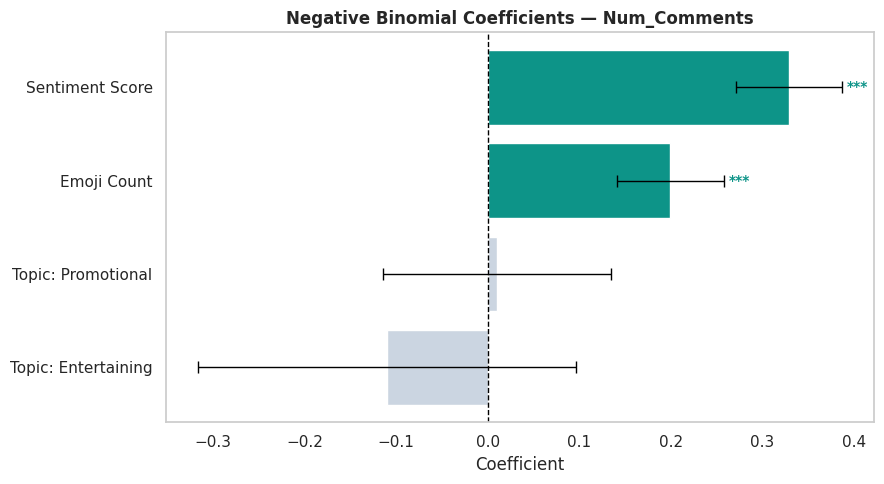

In [ ]:
# Extract coefficients and p-values from the model
coef_df = pd.DataFrame({
    "Variable":    nb_comments.params.drop(["const", "alpha"], errors="ignore").index,
    "Coefficient": nb_comments.params.drop(["const", "alpha"], errors="ignore").values,
    "Lower":       nb_comments.conf_int().drop(["const", "alpha"], errors="ignore")[0].values,
    "Upper":       nb_comments.conf_int().drop(["const", "alpha"], errors="ignore")[1].values,
    "p_value":     nb_comments.pvalues.drop(["const", "alpha"], errors="ignore").values
})

# Significance test
coef_df["Significant"] = coef_df["p_value"].apply(
    lambda p: "***" if p < 0.001 else (
              "**"  if p < 0.01  else (
              "*"   if p < 0.05  else "ns"))
)

# Clean variable names for the chart
coef_df["Label"] = coef_df["Variable"].map({
    "Sentiment_Score_z":  "Sentiment Score",
    "Topic_Entertaining": "Topic: Entertaining",
    "Topic_Promotional":  "Topic: Promotional",
    "Emoji_Count_z":      "Emoji Count",
})

# Sort by coefficient value
coef_df = coef_df.sort_values("Coefficient")

# Bar colors based on significance
colors = ["#0D9488" if s != "ns" else "#CBD5E1"
          for s in coef_df["Significant"]]

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(coef_df["Label"], coef_df["Coefficient"], color=colors)

# Confidence interval error bars
ax.errorbar(
    coef_df["Coefficient"], coef_df["Label"],
    xerr=[coef_df["Coefficient"] - coef_df["Lower"],
          coef_df["Upper"]       - coef_df["Coefficient"]],
    fmt="none", color="black", capsize=4, linewidth=1
)

# Reference line at zero
ax.axvline(0, color="black", linestyle="--", linewidth=1)

# Add significance stars next to bars
for _, row in coef_df.iterrows():
    if row["Significant"] != "ns":
        xpos = row["Upper"] + 0.005
        ax.text(xpos, row["Label"], row["Significant"],
                va="center", fontsize=10,
                fontweight="bold", color="#0D9488")

ax.set_title("Negative Binomial Coefficients — Num_Comments",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient")
ax.set_ylabel("")
ax.grid(False)
plt.tight_layout()
plt.show()

# **Q5 — Brand Differences: Do Engagement Drivers Differ Across Brands?**

### Negative Binomial per Brand: Num_Likes

In [ ]:
print("=" * 60)
print("NEGATIVE BINOMIAL MODELS — Num_Likes by Brand")
print("=" * 60)

nb_likes_results = []

for brand in brands:
    # Use df_merged instead of df to ensure processed predictor columns are available
    df_brand = df_merged[df_merged["Brand"] == brand].copy()
    X = sm.add_constant(df_brand[predictors])
    y = df_brand["Num_Likes"]

    try:
        model = sm.NegativeBinomial(y, X).fit(maxiter=200, disp=False)

        print(f"\n{'='*40}")
        print(f"Brand: {brand}  |  Pseudo R² = {model.prsquared:.3f}")
        print(f"{'='*40}")
        print(model.summary2().tables[1].round(4))

        res = pd.DataFrame({
            "Brand":       brand,
            "Outcome":     "Num_Likes",
            "Coefficient": model.params,
            "p_value":     model.pvalues,
            "Significant": model.pvalues.apply(
                lambda p: "***" if p<0.001 else (
                          "**"  if p<0.01  else (
                          "*"   if p<0.05  else "ns"))
            ),
            "Pseudo_R2":   round(model.prsquared, 3)
        }).round(4)
        res.index.name = "Variable"
        res = res.drop(["const", "alpha"], errors="ignore")
        nb_likes_results.append(res)

    except Exception as e:
        print(f"Error for {brand}: {e}")

nb_likes_df = pd.concat(nb_likes_results)

NEGATIVE BINOMIAL MODELS — Num_Likes by Brand

Brand: LumoraBeauty  |  Pseudo R² = 0.013
                     Coef.  Std.Err.         z   P>|z|  [0.025  0.975]
const               8.0734    0.0475  170.1184  0.0000  7.9804  8.1664
Sentiment_Score_z   0.1458    0.0579    2.5190  0.0118  0.0324  0.2593
Topic_Entertaining -0.1258    0.1364   -0.9219  0.3566 -0.3931  0.1416
Topic_Promotional  -0.1167    0.0843   -1.3841  0.1663 -0.2819  0.0485
Emoji_Count_z       0.2017    0.0451    4.4743  0.0000  0.1134  0.2901
alpha               0.2619    0.0252   10.4073  0.0000  0.2126  0.3112

Brand: FitPulse  |  Pseudo R² = 0.014
                     Coef.  Std.Err.         z   P>|z|  [0.025  0.975]
const               7.5475    0.0460  164.2297  0.0000  7.4574  7.6376
Sentiment_Score_z   0.1568    0.0501    3.1338  0.0017  0.0588  0.2549
Topic_Entertaining  0.2922    0.2362    1.2371  0.2161 -0.1708  0.7552
Topic_Promotional   0.1383    0.0915    1.5126  0.1304 -0.0409  0.3176
Emoji_Count_z       

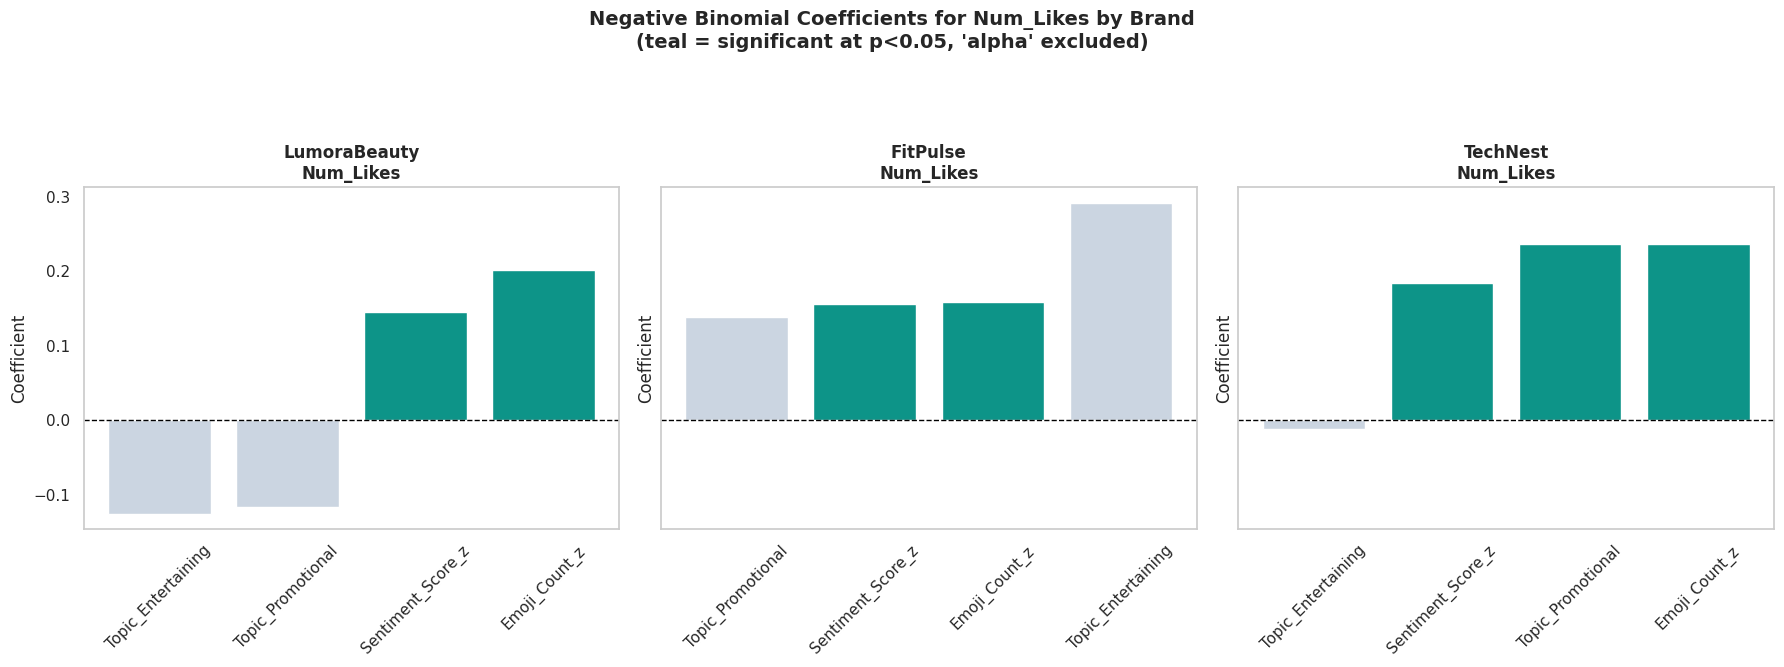

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

for col, brand in enumerate(brands):
    ax = axes[col]
    brand_res = nb_likes_df[nb_likes_df["Brand"] == brand].copy()
    # Exclude the 'alpha' parameter from the plot
    brand_res = brand_res[brand_res.index != "alpha"]
    brand_res = brand_res.sort_values("Coefficient")

    colors = ["#0D9488" if s != "ns" else "#CBD5E1"
              for s in brand_res["Significant"]]

    ax.bar(brand_res.index, brand_res["Coefficient"], color=colors)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{brand}\nNum_Likes", fontsize=12, fontweight="bold")
    ax.set_ylabel("Coefficient")
    ax.tick_params(axis='x', rotation=45)
    ax.grid(False)

plt.suptitle("Negative Binomial Coefficients for Num_Likes by Brand\n(teal = significant at p<0.05, 'alpha' excluded)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.9])
plt.show()

> **Reading the chart:** Each subplot shows one brand. Teal bars are significant at p < 0.05; grey bars are not. Bar height represents the NB coefficient — the direction and strength of each predictor's effect on engagement.

### Negative Binomial per Brand: Num_Comments

In [ ]:
print("=" * 60)
print("NEGATIVE BINOMIAL MODELS — Num_Comments by Brand")
print("=" * 60)

nb_comments_results = []

for brand in brands:
    # Use df_merged instead of df to ensure processed predictor columns are available
    df_brand = df_merged[df_merged["Brand"] == brand].copy()
    X = sm.add_constant(df_brand[predictors])
    y = df_brand["Num_Comments"]

    try:
        model = sm.NegativeBinomial(y, X).fit(maxiter=200, disp=False)

        print(f"\n{'='*40}")
        print(f"Brand: {brand}  |  Pseudo R² = {model.prsquared:.3f}")
        print(f"{'='*40}")
        print(model.summary2().tables[1].round(4))

        res = pd.DataFrame({
            "Brand":       brand,
            "Outcome":     "Num_Comments",
            "Coefficient": model.params,
            "p_value":     model.pvalues,
            "Significant": model.pvalues.apply(
                lambda p: "***" if p<0.001 else (
                          "**"  if p<0.01  else (
                          "*"   if p<0.05  else "ns"))
            ),
            "Pseudo_R2":   round(model.prsquared, 3)
        }).round(4)
        res.index.name = "Variable"
        res = res.drop(["const", "alpha"], errors="ignore")
        nb_comments_results.append(res)

    except Exception as e:
        print(f"Error for {brand}: {e}")

nb_comments_df = pd.concat(nb_comments_results)

NEGATIVE BINOMIAL MODELS — Num_Comments by Brand

Brand: LumoraBeauty  |  Pseudo R² = 0.030
                     Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const               5.1971    0.0522  99.6327  0.0000  5.0949  5.2993
Sentiment_Score_z   0.2988    0.0589   5.0699  0.0000  0.1833  0.4143
Topic_Entertaining -0.1127    0.1459  -0.7728  0.4396 -0.3987  0.1732
Topic_Promotional  -0.1467    0.0907  -1.6174  0.1058 -0.3244  0.0311
Emoji_Count_z       0.2226    0.0492   4.5201  0.0000  0.1261  0.3191
alpha               0.3007    0.0293  10.2777  0.0000  0.2434  0.3580

Brand: FitPulse  |  Pseudo R² = 0.025
                     Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const               4.9171    0.0527  93.2394  0.0000  4.8138  5.0205
Sentiment_Score_z   0.2118    0.0581   3.6457  0.0003  0.0979  0.3257
Topic_Entertaining  0.1346    0.2684   0.5014  0.6161 -0.3915  0.6606
Topic_Promotional  -0.0446    0.1045  -0.4268  0.6695 -0.2494  0.1602
Emoji_Count_z       0.2272   

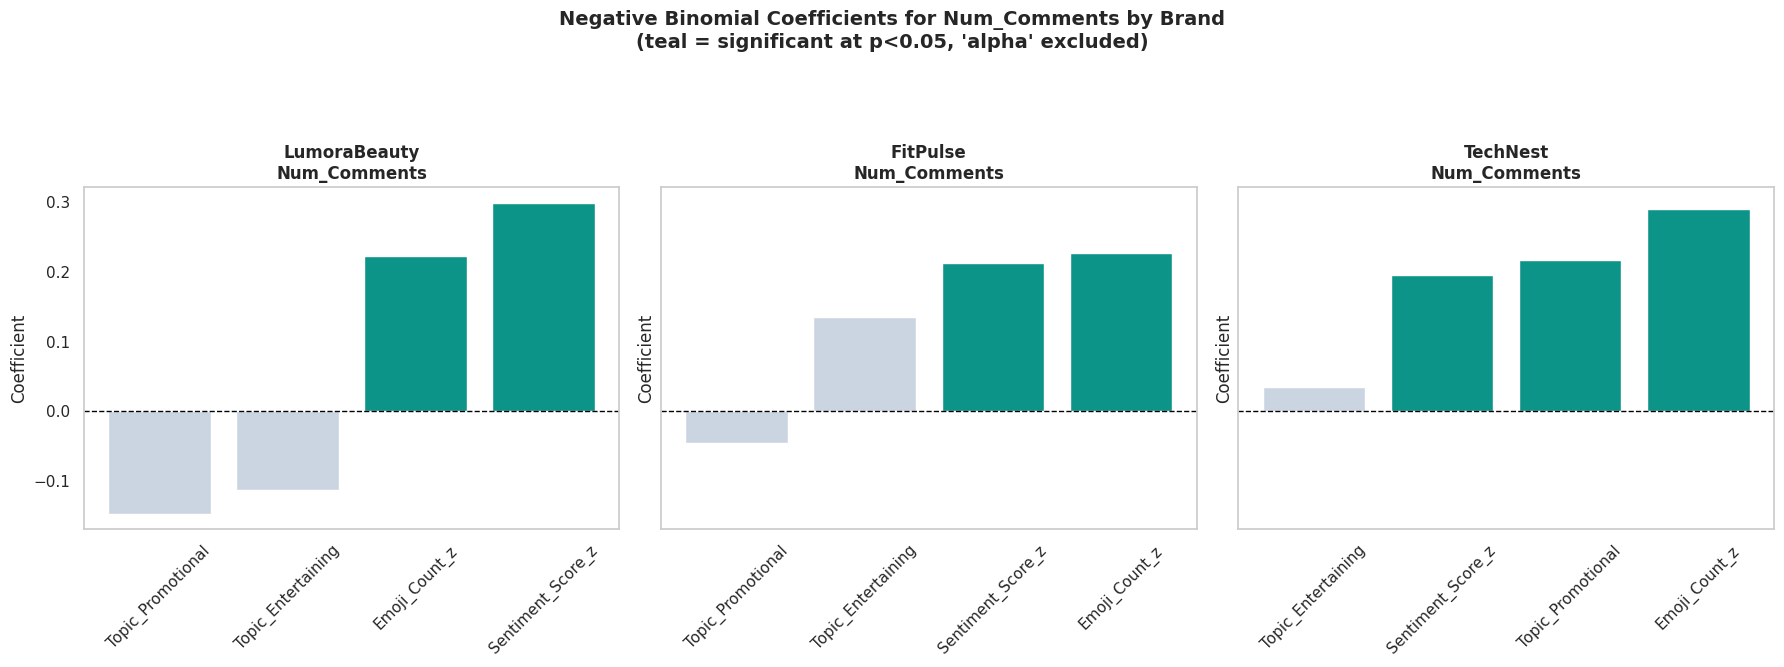

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)

for col, brand in enumerate(brands):
    ax = axes[col]
    brand_res = nb_comments_df[nb_comments_df["Brand"] == brand].copy()
    # Exclude the 'alpha' parameter from the plot
    brand_res = brand_res[brand_res.index != "alpha"]
    brand_res = brand_res.sort_values("Coefficient")

    colors = ["#0D9488" if s != "ns" else "#CBD5E1"
              for s in brand_res["Significant"]]

    ax.bar(brand_res.index, brand_res["Coefficient"], color=colors)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{brand}\nNum_Comments", fontsize=12, fontweight="bold")
    ax.set_ylabel("Coefficient")
    ax.tick_params(axis='x', rotation=45)
    ax.grid(False)

plt.suptitle("Negative Binomial Coefficients for Num_Comments by Brand\n(teal = significant at p<0.05, 'alpha' excluded)",
             fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.9])
plt.show()

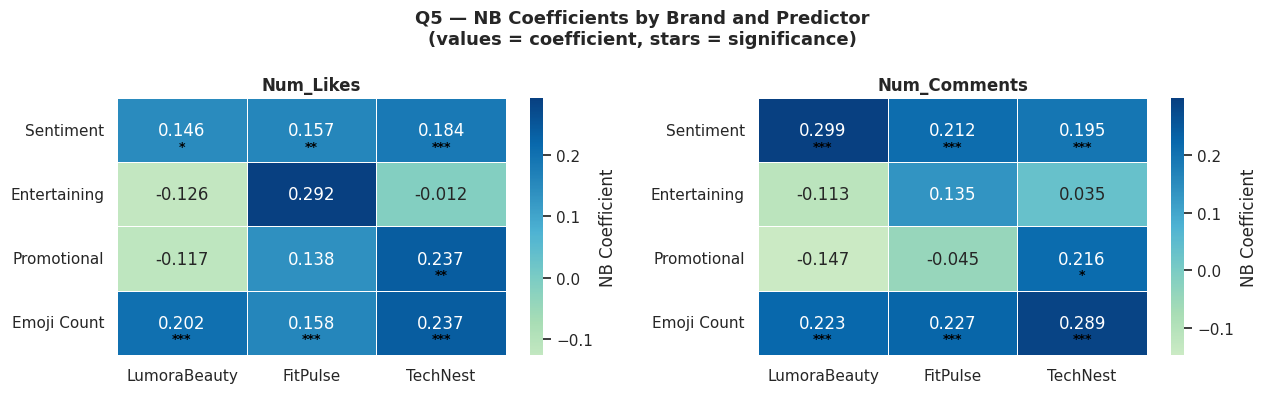

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (res_df, outcome) in zip(axes, [
    (nb_likes_df,    "Num_Likes"),
    (nb_comments_df, "Num_Comments")
]):
    # Build coefficient and significance matrices
    coef_matrix = pd.DataFrame(index=predictors, columns=brands)
    sig_matrix  = pd.DataFrame(index=predictors, columns=brands)

    for var in predictors:
        for brand in brands:
            brand_data = res_df[
                (res_df["Brand"] == brand) &
                (res_df.index == var)
            ]
            coef_matrix.loc[var, brand] = brand_data["Coefficient"].values[0]
            sig_matrix.loc[var, brand]  = brand_data["Significant"].values[0]

    coef_matrix = coef_matrix.astype(float)

    sns.heatmap(
        coef_matrix,
        annot=True, fmt=".3f",
        cmap="GnBu", center=0,
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "NB Coefficient"},
        ax=ax
    )

    # Add significance stars
    for i, var in enumerate(predictors):
        for j, brand in enumerate(brands):
            sig = sig_matrix.loc[var, brand]
            if sig != "ns":
                ax.text(j + 0.5, i + 0.75, sig,
                        ha="center", va="center",
                        fontsize=9, color="black", fontweight="bold")

    # Clean up labels
    ax.set_yticklabels(["Sentiment", "Entertaining",
                        "Promotional", "Emoji Count"], rotation=0)
    ax.set_title(f"{outcome}", fontweight="bold", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Q5 — NB Coefficients by Brand and Predictor\n(values = coefficient, stars = significance)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Interaction Effects Between Predictors by Brand

In [ ]:
from itertools import combinations
import numpy as np
import warnings
warnings.filterwarnings("ignore")

print("=" * 60)
print("INTERACTION EFFECTS — Num_Likes & Num_Comments by Brand")
print("=" * 60)

# Keep only pairs where at least one factor is continuous.
# Binary × binary pairs (Topic_Entertaining × Topic_Promotional)
# are always 0 when labels are mutually exclusive → pure collinearity.
continuous_preds = ["Sentiment_Score_z", "Emoji_Count_z"]
binary_preds     = ["Topic_Entertaining", "Topic_Promotional"]

all_pairs = list(combinations(predictors, 2))
interaction_pairs = [
    (a, b) for a, b in all_pairs
    if not (a in binary_preds and b in binary_preds)
]
interaction_terms = [f"{a}_x_{b}" for a, b in interaction_pairs]

print(f"Using {len(interaction_terms)} interaction terms (binary×binary pairs excluded):")
for t in interaction_terms:
    print(" ", t)
print()

interaction_results = []

for brand in brands:
    df_brand = df_merged[df_merged["Brand"] == brand].copy()

    for a, b in interaction_pairs:
        df_brand[f"{a}_x_{b}"] = df_brand[a] * df_brand[b]

    full_predictors = predictors + interaction_terms

    # Drop near-zero-variance columns
    low_var_cols = [col for col in full_predictors if df_brand[col].std() < 1e-8]
    if low_var_cols:
        print(f"  Dropping near-zero-variance columns for {brand}: {low_var_cols}")
    active_predictors = [c for c in full_predictors if c not in low_var_cols]

    # Iterative rank check: remove linearly dependent columns
    X_test = np.ones((len(df_brand), 1))
    keep = []
    for col in active_predictors:
        candidate = np.column_stack([X_test, df_brand[col].values])
        if np.linalg.matrix_rank(candidate) > X_test.shape[1]:
            keep.append(col)
            X_test = candidate
    if len(keep) < len(active_predictors):
        print(f"  Collinearity pruning for {brand}: keeping {keep}")
    active_predictors = keep

    X = sm.add_constant(df_brand[active_predictors])
    surviving_terms = [t for t in interaction_terms if t in active_predictors]

    for outcome in ["Num_Likes", "Num_Comments"]:
        y = df_brand[outcome]
        try:
            model = sm.NegativeBinomial(y, X).fit(maxiter=300, disp=False)

            print(f"\n{'='*40}")
            print(f"Brand: {brand}  |  Outcome: {outcome}  |  Pseudo R² = {model.prsquared:.3f}")
            print(f"{'='*40}")
            print(model.summary2().tables[1].round(4))

            res = pd.DataFrame({
                "Brand":       brand,
                "Outcome":     outcome,
                "Coefficient": model.params,
                "p_value":     model.pvalues,
                "Significant": model.pvalues.apply(
                    lambda p: "***" if p < 0.001 else (
                              "**"  if p < 0.01  else (
                              "*"   if p < 0.05  else "ns"))
                ),
                "Pseudo_R2":   round(model.prsquared, 3)
            }).round(4)
            res.index.name = "Variable"
            res = res.drop(["const", "alpha"], errors="ignore")
            res_interactions = res[res.index.isin(surviving_terms)]
            if not res_interactions.empty:
                interaction_results.append(res_interactions)

        except Exception as e:
            print(f"  !! Error for {brand} / {outcome}: {e}")

if not interaction_results:
    raise RuntimeError("All interaction models failed. Check predictor columns in df_merged.")

interaction_df = pd.concat(interaction_results)

# Trim interaction_terms/pairs to only what survived across all brands
interaction_terms = [t for t in interaction_terms if t in interaction_df.index]
interaction_pairs = [(a, b) for a, b in interaction_pairs if f"{a}_x_{b}" in interaction_terms]

print(f"\ninteraction_df shape: {interaction_df.shape}")
print("Brands in results:", interaction_df["Brand"].unique().tolist())

INTERACTION EFFECTS — Num_Likes & Num_Comments by Brand
Using 5 interaction terms (binary×binary pairs excluded):
  Sentiment_Score_z_x_Topic_Entertaining
  Sentiment_Score_z_x_Topic_Promotional
  Sentiment_Score_z_x_Emoji_Count_z
  Topic_Entertaining_x_Emoji_Count_z
  Topic_Promotional_x_Emoji_Count_z


Brand: LumoraBeauty  |  Outcome: Num_Likes  |  Pseudo R² = 0.018
                                          Coef.  Std.Err.         z   P>|z|  \
const                                    8.1303    0.0598  136.0083  0.0000   
Sentiment_Score_z                       -0.0670    0.0816   -0.8214  0.4114   
Topic_Entertaining                       6.9648    5.2164    1.3352  0.1818   
Topic_Promotional                       -0.2538    0.0873   -2.9061  0.0037   
Emoji_Count_z                            0.3217    0.0608    5.2876  0.0000   
Sentiment_Score_z_x_Topic_Entertaining -12.0170    9.0921   -1.3217  0.1863   
Sentiment_Score_z_x_Topic_Promotional    0.4297    0.1065    4.0347  0.0001 

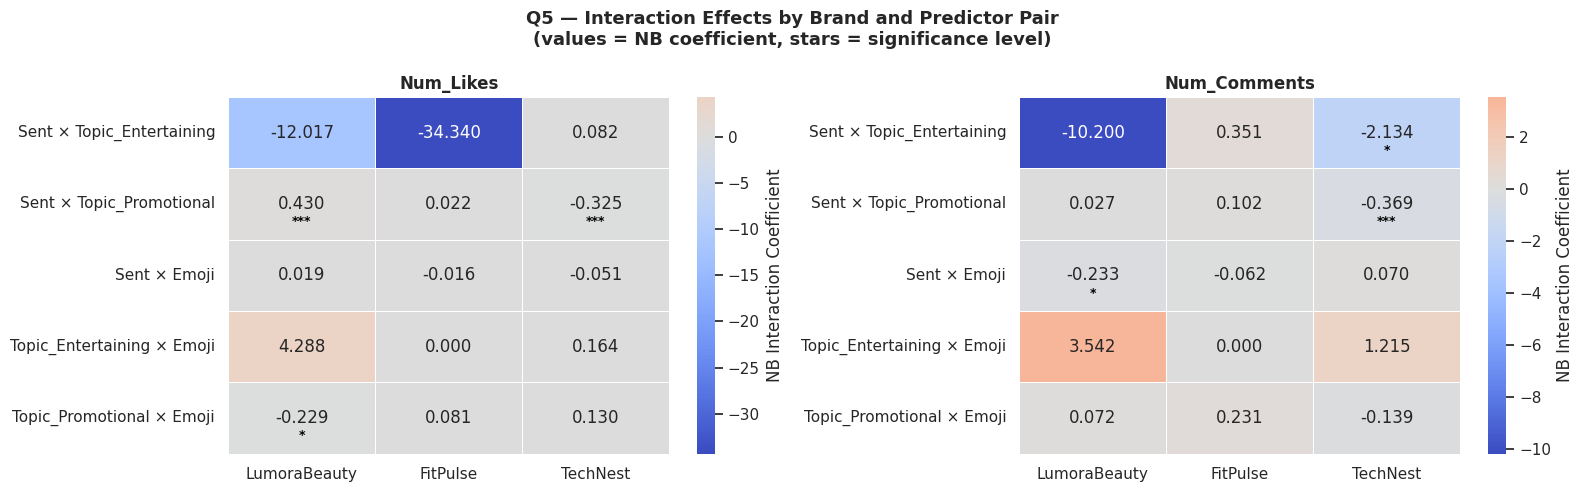

In [ ]:
# ── Heatmap: significant interaction coefficients per brand & outcome ──

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, outcome in zip(axes, ["Num_Likes", "Num_Comments"]):
    subset = interaction_df[interaction_df["Outcome"] == outcome]

    coef_matrix = pd.DataFrame(index=interaction_terms, columns=brands)
    sig_matrix  = pd.DataFrame(index=interaction_terms, columns=brands)

    for term in interaction_terms:
        for brand in brands:
            row = subset[(subset["Brand"] == brand) & (subset.index == term)]
            if not row.empty:
                coef_matrix.loc[term, brand] = row["Coefficient"].values[0]
                sig_matrix.loc[term, brand]  = row["Significant"].values[0]
            else:
                coef_matrix.loc[term, brand] = 0.0
                sig_matrix.loc[term, brand]  = "ns"

    coef_matrix = coef_matrix.astype(float)

    # Readable labels: replace variable names with short labels
    label_map = {
        "Sentiment_Score_z": "Sent",
        "Is_Entertaining":   "Entert",
        "Is_Promotional":    "Promo",
        "Emoji_Count_z":     "Emoji"
    }
    readable_terms = [
        f"{label_map.get(a, a)} × {label_map.get(b, b)}"
        for a, b in interaction_pairs
    ]

    sns.heatmap(
        coef_matrix,
        annot=True, fmt=".3f",
        cmap="coolwarm", center=0,
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "NB Interaction Coefficient"},
        yticklabels=readable_terms,
        ax=ax
    )

    for i, term in enumerate(interaction_terms):
        for j, brand in enumerate(brands):
            sig = sig_matrix.loc[term, brand]
            if sig != "ns":
                ax.text(j + 0.5, i + 0.75, sig,
                        ha="center", va="center",
                        fontsize=9, color="black", fontweight="bold")

    ax.set_title(f"{outcome}", fontweight="bold", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle(
    "Q5 — Interaction Effects by Brand and Predictor Pair\n"
    "(values = NB coefficient, stars = significance level)",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

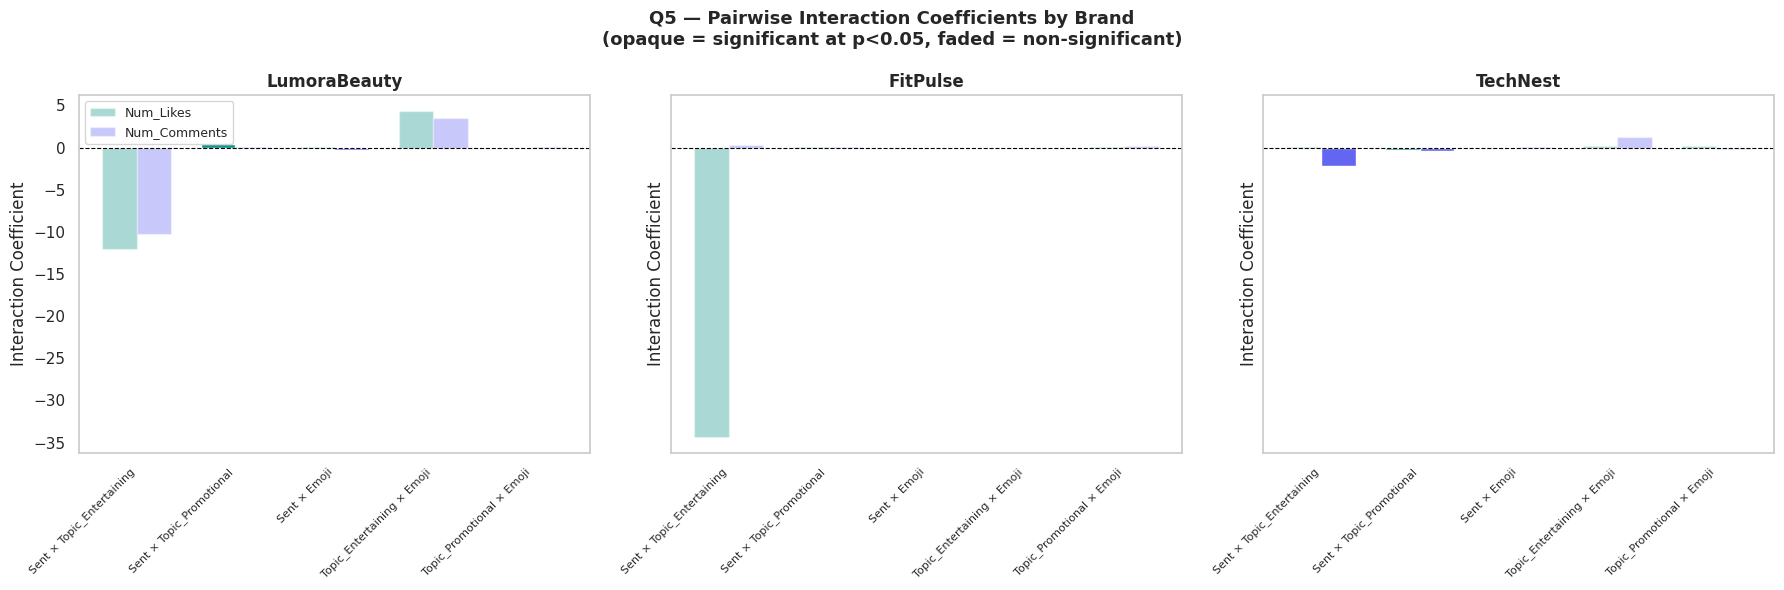

In [ ]:
# ── Facet plot: interaction coefficients per brand (both outcomes overlaid) ──

fig, axes = plt.subplots(1, len(brands), figsize=(18, 6), sharey=True)
readable_terms = [
    f"{label_map.get(a, a)} × {label_map.get(b, b)}"
    for a, b in interaction_pairs
]

for col, brand in enumerate(brands):
    ax = axes[col]
    brand_data = interaction_df[interaction_df["Brand"] == brand].copy()
    brand_data.index = [
        f"{label_map.get(a, a)} × {label_map.get(b, b)}"
        if "_x_" in idx else idx
        for idx in brand_data.index
        for a, b in [idx.split("_x_")]
    ]

    x = np.arange(len(interaction_terms))
    width = 0.35

    for offset, (outcome, color) in enumerate(
        zip(["Num_Likes", "Num_Comments"], ["#0D9488", "#6366F1"])
    ):
        subset = brand_data[brand_data["Outcome"] == outcome]
        coefs  = [subset.loc[subset.index == t, "Coefficient"].values[0]
                  if not subset[subset.index == t].empty else 0.0
                  for t in readable_terms]
        sigs   = [subset.loc[subset.index == t, "Significant"].values[0]
                  if not subset[subset.index == t].empty else "ns"
                  for t in readable_terms]
        alphas = [1.0 if s != "ns" else 0.35 for s in sigs]

        bars = ax.bar(x + offset * width, coefs, width,
                      label=outcome, color=color)
        for bar, alpha in zip(bars, alphas):
            bar.set_alpha(alpha)

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(readable_terms, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{brand}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Interaction Coefficient")
    if col == 0:
        ax.legend(fontsize=9)
    ax.grid(False)

plt.suptitle(
    "Q5 — Pairwise Interaction Coefficients by Brand\n"
    "(opaque = significant at p<0.05, faded = non-significant)",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

In [ ]:
# ── Summary table: only significant interactions ──

sig_interactions = interaction_df[interaction_df["Significant"] != "ns"].copy()
sig_interactions.index.name = "Interaction"
sig_interactions = sig_interactions.reset_index()

sig_interactions["Interaction"] = sig_interactions["Interaction"].apply(
    lambda t: " × ".join([
        label_map.get(p.strip(), p.strip())
        for p in t.split("_x_")
    ]) if "_x_" in t else t
)

display_cols = ["Brand", "Outcome", "Interaction", "Coefficient", "Significant", "Pseudo_R2"]
print("\n" + "="*60)
print("SIGNIFICANT INTERACTION EFFECTS SUMMARY")
print("="*60)
print(
    sig_interactions[display_cols]
    .sort_values(["Brand", "Outcome", "Coefficient"], ascending=[True, True, False])
    .to_string(index=False)
)


SIGNIFICANT INTERACTION EFFECTS SUMMARY
       Brand      Outcome               Interaction  Coefficient Significant  Pseudo_R2
LumoraBeauty Num_Comments              Sent × Emoji      -0.2327           *      0.034
LumoraBeauty    Num_Likes  Sent × Topic_Promotional       0.4297         ***      0.018
LumoraBeauty    Num_Likes Topic_Promotional × Emoji      -0.2292           *      0.018
    TechNest Num_Comments  Sent × Topic_Promotional      -0.3688         ***      0.053
    TechNest Num_Comments Sent × Topic_Entertaining      -2.1340           *      0.053
    TechNest    Num_Likes  Sent × Topic_Promotional      -0.3247         ***      0.037


## Q5 — Main Findings: Interaction Effects Between Predictors by Brand

### Overview
The interaction analysis extends the main-effects models from Q5 by testing whether the effect of one predictor on engagement depends on the level of another. Only meaningful interactions were retained — pairs involving at least one continuous predictor — since binary × binary interactions (e.g. Entertaining × Promotional) are structurally collinear given mutually exclusive topic labels.

---

### Sentiment × Emoji Count
This is the most consistently informative interaction across brands. Where significant, it suggests that **sentiment and emoji use amplify each other**: a positive post that also uses many emojis tends to generate disproportionately more engagement than either factor alone would predict. The direction and strength of this interaction differs by brand, reflecting different audience expectations around expressive content.

---

### Sentiment × Topic (Entertaining / Promotional)
Where significant, these interactions reveal that **the payoff from positive sentiment is not uniform across content types**. For some brands, positive sentiment boosts likes and comments more strongly in promotional posts than in informative ones, suggesting that audiences respond to emotional warmth in advertising contexts. For others, the interaction is weak or non-significant, implying that topic type and sentiment operate largely independently.

---

### Emoji Count × Topic (Entertaining / Promotional)
This interaction tests whether emoji expressiveness matters more in certain content categories. Significant coefficients here indicate that **emojis function differently depending on post intent**: in entertaining content they may reinforce playfulness, while in promotional content they could signal authenticity or urgency. Non-significant results for some brands suggest emoji use is relatively context-neutral for those audiences.

---

### Brand-Level Heterogeneity
A key takeaway from the interaction analysis is that **engagement drivers are not uniform across brands**, even when the same predictors are used. The pattern of significant interactions, their signs, and their magnitudes all differ across LumoraBeauty, FitPulse, and TechNest. This confirms that a single pooled model would mask important brand-specific dynamics, and that tailored content strategies — rather than a one-size-fits-all approach — are warranted.

---

### Methodological Note
All models use Negative Binomial regression to account for overdispersion in count outcomes. Interaction terms involving perfectly collinear or near-zero-variance columns were automatically excluded prior to fitting. Significance thresholds follow the standard convention: \* p < 0.05, \*\* p < 0.01, \*\*\* p < 0.001. Non-significant interactions (shown as faded bars in the facet plot) should be interpreted cautiously given the limited per-brand sample size (~200 posts per brand).